## Neo4j 그래프 DB 구축과 GraphRAG — 기초부터 단계별로

> 교안 「Neo4j 그래프 DB 구축과 GraphRAG」의 실습 노트북입니다.

벡터 RAG(PostgreSQL + pgvector)는 **"비슷한 문장"** 을 찾는 데 강합니다. 이 노트북에서는 **"무엇이 무엇과 어떻게 연결되어 있는가"** 를 저장하고 찾는 그래프 DB를 처음부터 익히고, 그 장점을 RAG에 활용하는 GraphRAG까지 단계별로 실습합니다.

| 파트 | 단계 | 내용 | 확인할 그래프 DB의 장점 |
|---|---|---|---|
| **1부. 그래프 DB 기초** | 1 | 첫 그래프 만들기 | 노드·관계·속성 |
| | 2 | CREATE와 MERGE | 중복 없이 데이터 쌓기 |
| | 3 | 실습 데이터 구축 | 그림처럼 보이는 데이터 |
| | 4 | 패턴으로 찾기 | 관계를 그림처럼 질의 |
| | 5 | 멀티홉 질문 | ⭐ 여러 단계 관계를 한 번에 |
| | 6 | 경로 탐색 | ⭐ 몇 단계인지 몰라도 찾기 |
| | 7 | 집계·추천·영향 분석 | ⭐ 정확한 개수·목록 |
| | 8 | 유연한 스키마 | ⭐ 테이블 변경 없이 확장 |
| | 9 | 인덱스와 실행 계획 | 빠른 시작점 찾기 |
| **2부. GraphRAG** | 10 | GraphRAG 준비 | — |
| | 11 | 문서 → 지식 그래프 | LLM이 관계를 추출 |
| | 12 | 벡터 인덱스와 SEARCH 절 | pgvector와 같은 일을 Neo4j에서 |
| | 13 | 벡터 RAG vs GraphRAG | ⭐ 흩어진 사실을 이어서 답하기 |
| | 14 | Text2Cypher | ⭐ "모두", "몇 명"에 정확히 답하기 |
| | 15 | 보너스: 에이전트 | 질문에 맞는 검색 고르기 |

**실습 등장인물**: 유니코, 도우너, 둘리, 또치 (2부에서는 마이콜, 희동이가 합류합니다)

> **한눈에 보기**
> - 1부 Cypher: 노드·관계·속성, `CREATE` vs `MERGE` + 유일성 제약, 패턴 매칭, 멀티홉, `shortestPath`, 집계·추천·영향 분석, 유연한 스키마, `PROFILE`
> - 2부 GraphRAG: `SimpleKGPipeline`으로 문서 10개 → 지식 그래프, 벡터 인덱스 + `SEARCH` 절, `VectorCypherRetriever`(벡터로 찾고 그래프로 확장) vs 벡터 RAG
> - 개수·목록은 `Text2CypherRetriever`(스키마 + few-shot, 읽기 전용 실행), 에이전트가 두 검색 도구를 골라 쓰기
> - 실습 데이터의 인물·회사 이름은 교안의 가상 예제. 정리 문서: [그래프DB와GraphRAG.md](그래프DB와GraphRAG.md) · 강의 슬라이드 이미지 포함, 📝 정리 셀은 직접 정리

---
### 0. 실습 환경 준비

#### 0-1. Neo4j 실행 (Docker)
실습 폴더에 `docker-compose.yml`을 만들고 터미널에서 `docker compose up -d`로 실행합니다. (교안 3.3절)

```yaml
services:
  neo4j:
    image: neo4j:2026.09.0          # Community Edition (태그에 -enterprise 가 없으면 Community)
    container_name: neo4j-edu
    ports:
      - "7474:7474"                 # Neo4j Browser (웹 화면)
      - "7687:7687"                 # Bolt 프로토콜 (Python 드라이버가 접속)
    environment:
      NEO4J_AUTH: neo4j/edu-password-1234   # 사용자/비밀번호 (비밀번호 8자 이상)
      NEO4J_PLUGINS: '["apoc"]'             # APOC 플러그인 자동 설치 (LangChain·GraphRAG가 사용)
    volumes:
      - neo4j_data:/data            # 컨테이너를 지워도 데이터 유지
 
volumes:
  neo4j_data:
```

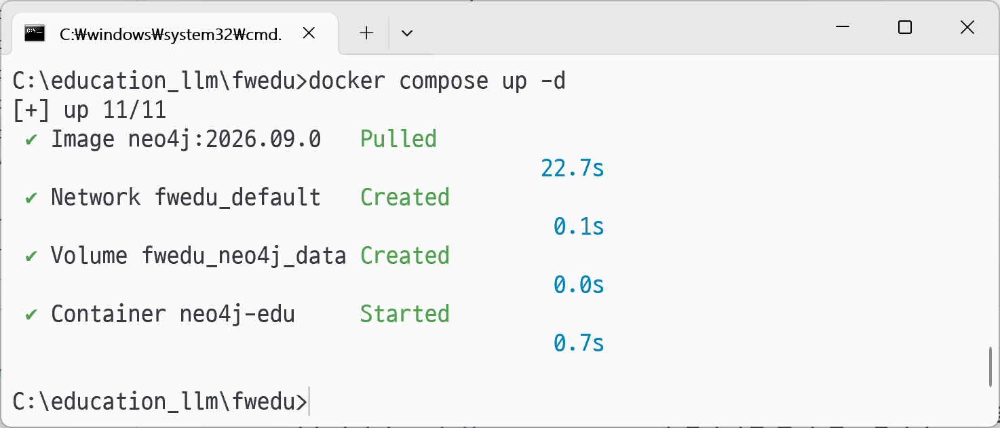


브라우저에서 `http://localhost:7474`에 접속되면 준비 완료입니다. 

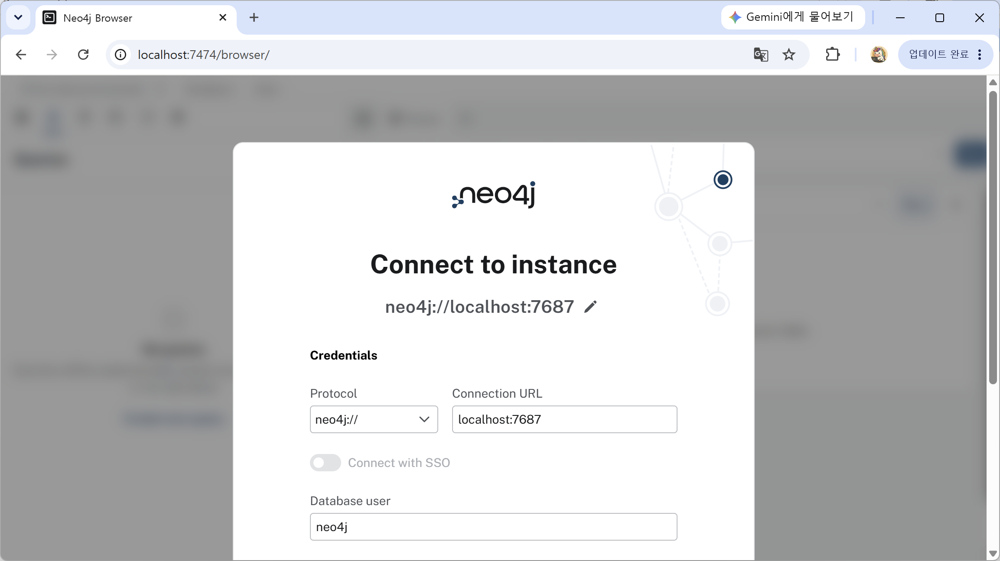

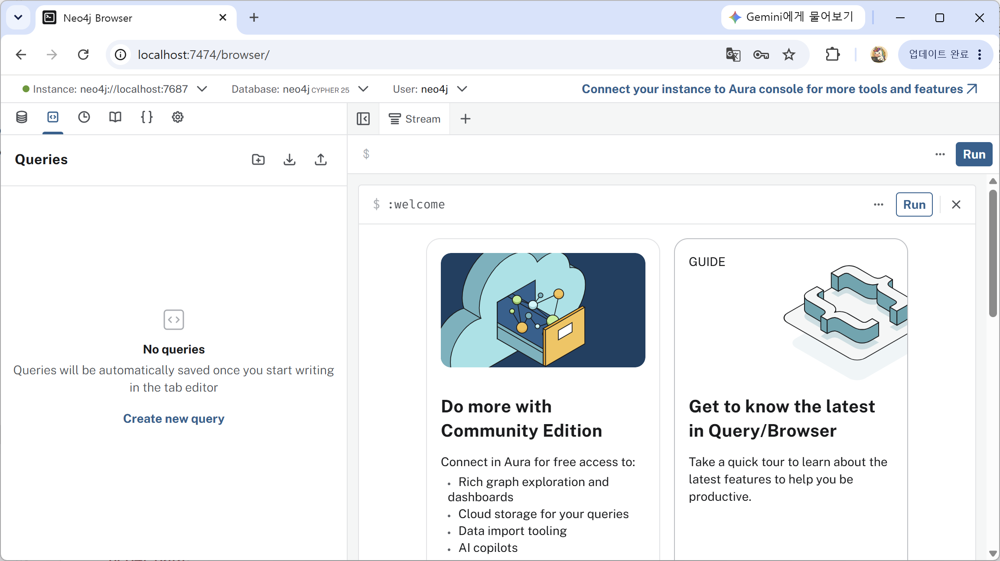

### 0-2. 환경변수 세팅
Windows 명령 프롬프트(cmd)에서 한 번만 실행합니다. `OPENAI_API_KEY`는 2부(GraphRAG)에서 사용합니다.
```
setx NEO4J_URI "neo4j://localhost:7687"
setx NEO4J_USERNAME "neo4j"
setx NEO4J_PASSWORD "edu-password-1234"
```
> ⚠️ `setx`로 저장한 값은 **새로 연 프로그램부터** 적용됩니다. 실행한 뒤에는 VS Code(또는 Jupyter)를 **완전히 종료했다가 다시 실행**해야 노트북에서 읽을 수 있습니다.

#### 0-3. 라이브러리 설치
**Python 3.12** 기준이며, 2026년 10월 최신 버전으로 고정했습니다. (Python 3.13에서도 동작합니다)

| 패키지 | 역할 |
|---|---|
| `neo4j` | Neo4j 공식 Python 드라이버 (Cypher 실행) |
| `neo4j-graphrag[openai]` | Neo4j 공식 GraphRAG 패키지 (지식 그래프 구축, 리트리버) |
| `pandas` | 조회 결과를 표로 보기 |
| `networkx`, `matplotlib` | 그래프를 노트북 안에서 그림으로 보기 |
| `langchain`, `langchain-openai` | 15단계 보너스(에이전트)에서 사용 |

In [1]:
%pip install -q \
    neo4j==6.4.1 \
    "neo4j-graphrag[openai]==1.22.0" \
    openai==3.39.0 \
    pandas==3.1.0 \
    networkx==3.7 \
    matplotlib==3.11.2 \
    langchain==1.4.7 \
    langchain-openai==1.7.3

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


> 💡 설치 후 "you may need to restart the kernel" 메시지가 보이면 **커널을 재시작**한 뒤 다음 셀부터 실행하세요.

### 0-4. Neo4j 연결과 공통 함수
노트북 전체에서 쓸 함수 두 개를 만듭니다.

| 함수 | 하는 일 |
|---|---|
| `run(query, **params)` | Cypher를 실행하고 결과를 **표(DataFrame)** 로 돌려줍니다 |
| `draw(query, **params)` | Cypher가 돌려준 노드·관계를 **그림** 으로 그립니다 |

<br>

> 💡 값은 항상 `$이름` 파라미터로 넘깁니다. 문자열을 이어 붙여 쿼리를 만들면 Cypher 인젝션 위험이 있습니다.

In [2]:
import os
import pandas as pd
from neo4j import GraphDatabase, Result, RoutingControl

# 환경변수 확인 — 비어 있으면 0-2 단계(setx 후 재시작)를 다시 확인
for key in ["NEO4J_URI", "NEO4J_USERNAME", "NEO4J_PASSWORD", "OPENAI_API_KEY"]:
    print(f"{key:15}: {'✅ 설정됨' if os.getenv(key) else '❌ 없음'}")

URI = os.getenv("NEO4J_URI", "neo4j://localhost:7687")
AUTH = (os.getenv("NEO4J_USERNAME", "neo4j"), os.getenv("NEO4J_PASSWORD"))

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()                                   # 접속이 안 되면 여기서 오류
print("\n✅ Neo4j 연결 성공 :", driver.get_server_info().agent)   # 예: Neo4j/2026.09.0

NEO4J_URI      : ✅ 설정됨
NEO4J_USERNAME : ✅ 설정됨
NEO4J_PASSWORD : ✅ 설정됨
OPENAI_API_KEY : ✅ 설정됨

✅ Neo4j 연결 성공 : Neo4j/2026.09.0


In [3]:
def run(query: str, **params) -> pd.DataFrame:
    # Cypher 를 실행하고 결과를 표(DataFrame)로 돌려준다
    return driver.execute_query(
        query, params,
        database_="neo4j",
        result_transformer_=Result.to_df,                     # 결과 → pandas DataFrame
    )

run("RETURN 'Hello, Graph!' AS 인사, 1 + 1 AS 계산")

,인사,계산
0,"Hello, Graph!",2


In [4]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 한글 폰트 설정 (Windows: 맑은 고딕 / macOS: AppleGothic / Linux: 나눔·Noto)
KFONT = "sans-serif"
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        KFONT = f
        break
plt.rcParams["font.family"] = KFONT
plt.rcParams["axes.unicode_minus"] = False

# 라벨별 색 (교안 그림과 같은 색)
LABEL_COLORS = {
    "Person": "#CECBF6", "Company": "#9FE1CB", "Project": "#F5C4B3",
    "Technology": "#FAC775", "Certificate": "#C0DD97", "Chunk": "#B5D4F4",
}


def draw(query: str, title: str = "", highlight: list[str] | None = None, **params):
    # Cypher 결과에 포함된 노드와 관계를 그림으로 그린다
    g = driver.execute_query(query, params, database_="neo4j", result_transformer_=Result.graph)

    G = nx.DiGraph()
    for n in g.nodes:
        labels = [l for l in n.labels if not l.startswith("__")]          # __Entity__ 같은 내부 라벨 제외
        label = next((l for l in labels if l in LABEL_COLORS), labels[0] if labels else "")
        name = n.get("name") or n.get("id") or label
        G.add_node(n.element_id, name=str(name), color=LABEL_COLORS.get(label, "#D3D1C7"))
    for r in g.relationships:
        u, v = r.start_node.element_id, r.end_node.element_id
        if G.has_edge(u, v):
            G[u][v]["type"] += "\n" + r.type
        else:
            G.add_edge(u, v, type=r.type)

    if G.number_of_nodes() == 0:
        print("(그릴 노드가 없습니다)")
        return

    pos = nx.spring_layout(G, seed=7, k=1.6 / max(G.number_of_nodes(), 1) ** 0.5)
    plt.figure(figsize=(11, 7))
    hl = set(highlight or [])
    edge_colors = ["#D85A30" if (G.nodes[u]["name"] in hl and G.nodes[v]["name"] in hl) else "#888780"
                   for u, v in G.edges]
    nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=1.6, arrowsize=16,
                           node_size=3400, connectionstyle="arc3,rad=0.06")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "type"),
                                 font_size=8, font_family=KFONT, font_color="#5F5E5A",
                                 bbox=dict(fc="white", ec="none", alpha=0.85))
    nx.draw_networkx_nodes(G, pos, node_size=3400, linewidths=1.5,
                           node_color=[G.nodes[n]["color"] for n in G.nodes],
                           edgecolors=["#D85A30" if G.nodes[n]["name"] in hl else "#5F5E5A" for n in G.nodes])
    nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, "name"),
                            font_size=9, font_family=KFONT, font_color="#2C2C2A")
    plt.title(title, fontsize=13)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

> ⚠️ **실습 DB 비우기**: 아래 셀은 데이터베이스의 **모든 노드와 관계를 삭제**합니다. 실습 전용 Neo4j에서만 실행하세요. 노트북을 처음부터 다시 실행할 때도 이 셀부터 시작하면 됩니다.

In [5]:
# 실습을 깨끗한 상태에서 시작 (이전 실습의 제약조건·인덱스도 정리)
run("MATCH (n) DETACH DELETE n")
for row in run("SHOW CONSTRAINTS YIELD name").itertuples():
    run(f"DROP CONSTRAINT {row.name} IF EXISTS")
for row in run("SHOW INDEXES YIELD name, type WHERE type IN ['VECTOR', 'FULLTEXT', 'RANGE']").itertuples():
    run(f"DROP INDEX {row.name} IF EXISTS")

run("MATCH (n) RETURN count(n) AS 남은노드수")

,남은노드수
0,0


---
## 1부. 그래프 DB 기초 — Cypher로 만들고, 찾고, 이해하기

### 1단계. 첫 그래프 만들기 — 노드, 관계, 속성

그래프는 네 가지로만 이루어집니다. (교안 2.1절)

| 구성 요소 | 의미 | Cypher 표기 |
|---|---|---|
| **노드** | 개체 (문장의 명사) | `(u)` |
| **라벨** | 노드의 종류 | `(u:Person)` |
| **관계** | 두 노드의 연결 (문장의 동사). 방향과 타입이 있음 | `-[:WORKS_AT]->` |
| **속성** | 노드·관계에 붙는 키-값 | `{name: '유니코'}` |

Cypher는 **그래프를 그림처럼 글로 쓰는 언어**입니다. 괄호 `()`는 동그란 노드, `-->`는 화살표를 닮았어요.

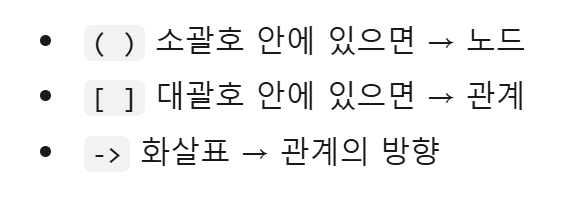

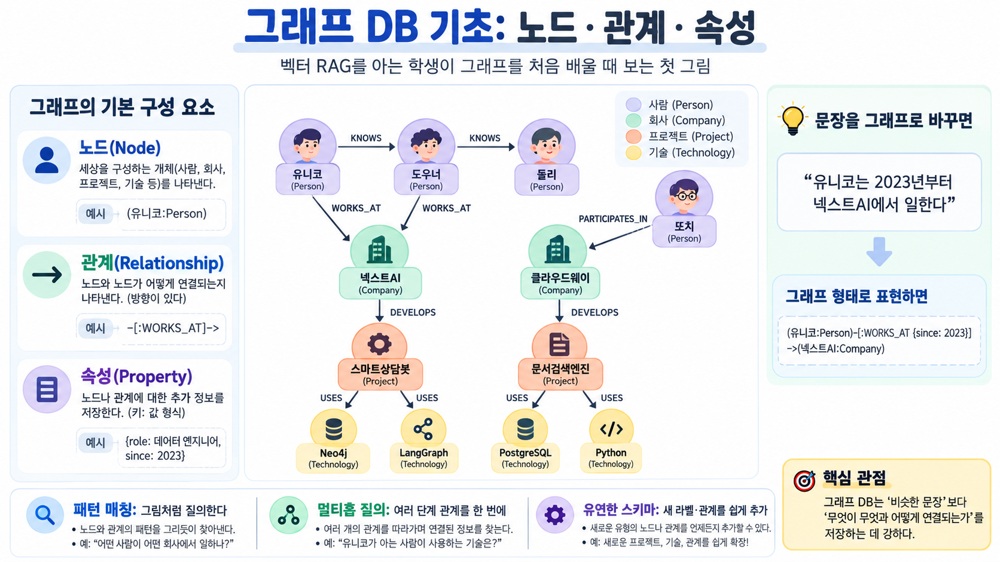

In [6]:
# "유니코는 2023년부터 넥스트AI에서 일한다" 를 그래프로 저장
run('''
CREATE (u:Person {name: '유니코', role: '데이터 엔지니어'})
CREATE (c:Company {name: '넥스트AI'})
CREATE (u)-[:WORKS_AT {since: 2023}]->(c)
''')

""


In [7]:
# 저장한 내용을 패턴으로 다시 찾기
run('''
MATCH (p:Person)-[r:WORKS_AT]->(c:Company)
RETURN p.name AS 사람, p.role AS 직무, r.since AS 입사연도, c.name AS 회사
''')

,사람,직무,입사연도,회사
0,유니코,데이터 엔지니어,2023,넥스트AI


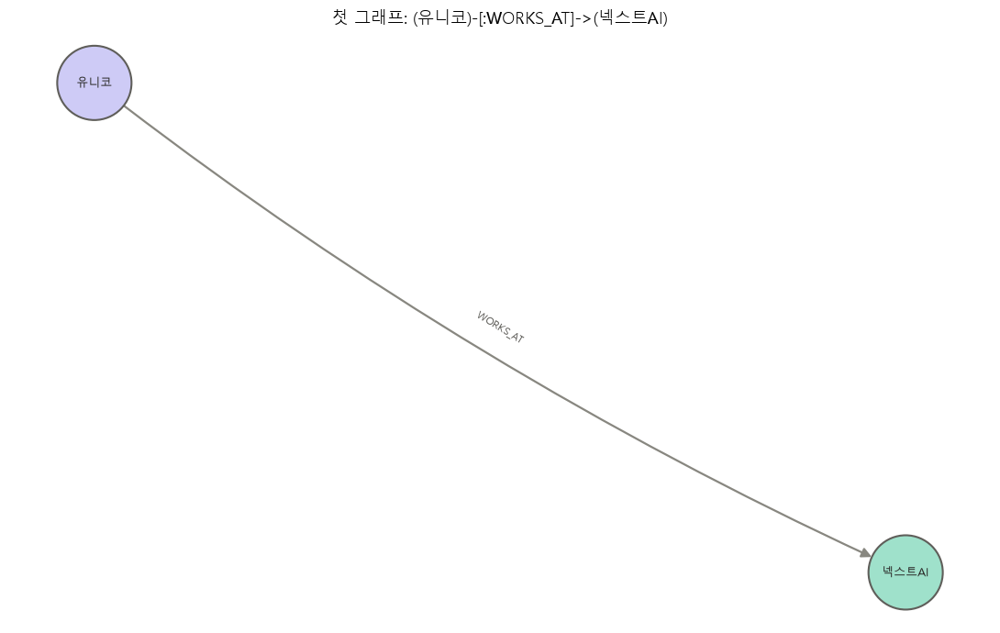

In [8]:
draw("MATCH (p)-[r]->(c) RETURN p, r, c", title="첫 그래프: (유니코)-[:WORKS_AT]->(넥스트AI)")

#### 속성 바꾸기(SET)와 삭제(DELETE)
- `SET` : 속성을 추가하거나 바꿉니다. **테이블 구조 변경(ALTER TABLE) 없이** 새 속성을 바로 붙일 수 있습니다.
- `DETACH DELETE` : 노드와 그 노드에 연결된 관계를 함께 지웁니다. (관계가 남은 노드는 `DELETE`만으로 지울 수 없습니다)

In [9]:
# 새 속성 추가 — 미리 정의하지 않은 속성도 바로 저장된다
run("MATCH (p:Person {name: '유니코'}) SET p.email = 'unico@nextai.example', p.level = 3")
display(run("MATCH (p:Person {name: '유니코'}) RETURN properties(p) AS 속성"))

# 연습이 끝났으니 모두 삭제
run("MATCH (n) DETACH DELETE n")
run("MATCH (n) RETURN count(n) AS 남은노드수")

,속성
0,"{'role': '데이터 엔지니어', 'level': 3, 'name': '유니코'..."


,남은노드수
0,0


### 2단계. CREATE와 MERGE — 중복의 함정 피하기

- `CREATE` : **실행할 때마다 무조건** 새로 만듭니다.
- `MERGE` : 같은 패턴이 **있으면 재사용, 없으면 생성**합니다.

같은 문장을 두 번 실행해 차이를 직접 확인해 봅니다.

In [10]:
# CREATE 를 두 번 실행
run("CREATE (:Person {name: '둘리'})")
run("CREATE (:Person {name: '둘리'})")
display(run("MATCH (p:Person {name: '둘리'}) RETURN count(p) AS `CREATE 두 번 → 둘리 수`"))    # 2명!

run("MATCH (n) DETACH DELETE n")

# MERGE 를 두 번 실행
run("MERGE (:Person {name: '둘리'})")
run("MERGE (:Person {name: '둘리'})")
display(run("MATCH (p:Person {name: '둘리'}) RETURN count(p) AS `MERGE 두 번 → 둘리 수`"))     # 1명

run("MATCH (n) DETACH DELETE n")

,CREATE 두 번 → 둘리 수
0,2


,MERGE 두 번 → 둘리 수
0,1


""


**📝 정리** — `CREATE` 두 번 → 둘리 2명(중복), `MERGE` 두 번 → 1명. 데이터 적재는 MERGE + 유일성 제약이 기본.

> 💡 **실무 규칙**
> 1. 데이터를 쌓을 때는 **MERGE + 유일성 제약조건** 조합을 기본으로 씁니다.
> 2. MERGE에는 **식별 속성(name)만** 쓰고, 나머지 속성은 `SET`으로 지정합니다.
>    `MERGE (p:Person {name:'유니코', role:'PM'})`처럼 쓰면 role이 다른 '유니코'를 새로 만들려고 합니다.

### 3단계. 실습 데이터 구축 (교안 4.3절)

교안의 실습 데이터를 그대로 사용합니다. 

| 라벨 | 노드 |
|---|---|
| Person | 유니코(데이터 엔지니어), 도우너(AI 엔지니어), 둘리(백엔드 개발자), 또치(PM) |
| Company | 넥스트AI, 클라우드웨이 |
| Project | 스마트상담봇(2026), 문서검색엔진(2025) |
| Technology | Neo4j, LangGraph, PostgreSQL, Python |

관계: `WORKS_AT`, `KNOWS`, `DEVELOPS`, `USES`, `HAS_SKILL`, `PARTICIPATES_IN`

#### ① 제약조건 먼저
같은 이름의 노드가 두 번 생기지 않게 **유일성 제약조건**을 만듭니다. 제약조건을 만들면 그 속성에 **인덱스도 자동으로** 생겨서 이름으로 찾는 속도도 빨라집니다.

In [11]:
for label in ["Person", "Company", "Project", "Technology"]:
    run(f"CREATE CONSTRAINT {label.lower()}_name IF NOT EXISTS FOR (n:{label}) REQUIRE n.name IS UNIQUE")

run("SHOW CONSTRAINTS YIELD name, labelsOrTypes, properties, type")

,name,labelsOrTypes,properties,type
0,company_name,[Company],[name],NODE_PROPERTY_UNIQUENESS
1,person_name,[Person],[name],NODE_PROPERTY_UNIQUENESS
2,project_name,[Project],[name],NODE_PROPERTY_UNIQUENESS
3,technology_name,[Technology],[name],NODE_PROPERTY_UNIQUENESS


#### ② 노드와 관계 만들기
`MERGE`로 노드를 만들고 변수(`kim`, `next` …)에 담아 두면, 같은 쿼리 안에서 그 변수로 관계를 연결할 수 있습니다.

In [12]:
DATASET = '''
MERGE (kim:Person  {name: '유니코'}) SET kim.role  = '데이터 엔지니어'
MERGE (lee:Person  {name: '도우너'}) SET lee.role  = 'AI 엔지니어'
MERGE (park:Person {name: '둘리'})   SET park.role = '백엔드 개발자'
MERGE (choi:Person {name: '또치'})   SET choi.role = 'PM'
MERGE (next:Company  {name: '넥스트AI'})     SET next.industry  = 'AI 상담'
MERGE (cloud:Company {name: '클라우드웨이'}) SET cloud.industry = '클라우드'
MERGE (bot:Project    {name: '스마트상담봇'}) SET bot.startYear    = 2026
MERGE (search:Project {name: '문서검색엔진'}) SET search.startYear = 2025
MERGE (neo:Technology {name: 'Neo4j'})
MERGE (lg:Technology  {name: 'LangGraph'})
MERGE (pg:Technology  {name: 'PostgreSQL'})
MERGE (py:Technology  {name: 'Python'})
MERGE (kim)-[:WORKS_AT {since: 2023}]->(next)
MERGE (lee)-[:WORKS_AT {since: 2024}]->(next)
MERGE (park)-[:WORKS_AT {since: 2022}]->(cloud)
MERGE (choi)-[:WORKS_AT {since: 2021}]->(cloud)
MERGE (kim)-[:KNOWS]->(lee)
MERGE (lee)-[:KNOWS]->(park)
MERGE (next)-[:DEVELOPS]->(bot)
MERGE (cloud)-[:DEVELOPS]->(search)
MERGE (bot)-[:USES]->(neo)
MERGE (bot)-[:USES]->(lg)
MERGE (search)-[:USES]->(pg)
MERGE (search)-[:USES]->(py)
MERGE (kim)-[:HAS_SKILL]->(py)
MERGE (kim)-[:HAS_SKILL]->(neo)
MERGE (lee)-[:HAS_SKILL]->(lg)
MERGE (park)-[:HAS_SKILL]->(pg)
MERGE (kim)-[:PARTICIPATES_IN]->(bot)
MERGE (lee)-[:PARTICIPATES_IN]->(bot)
MERGE (park)-[:PARTICIPATES_IN]->(search)
MERGE (choi)-[:PARTICIPATES_IN]->(search)
'''

summary = driver.execute_query(DATASET, database_="neo4j").summary
print(summary.counters)          # 만들어진 노드·관계·속성 수

SummaryCounters{labels_added: 12, relationships_created: 20, nodes_created: 12, properties_set: 24, contains_updates: True, contains_system_updates: False}


**📝 정리** — 노드 12개, 관계 20개. 다시 실행해도 MERGE라 늘지 않는다.

> 💡 위 셀을 **한 번 더 실행해 보세요.** `MERGE`라서 노드와 관계가 더 늘어나지 않습니다. (counters가 거의 0)

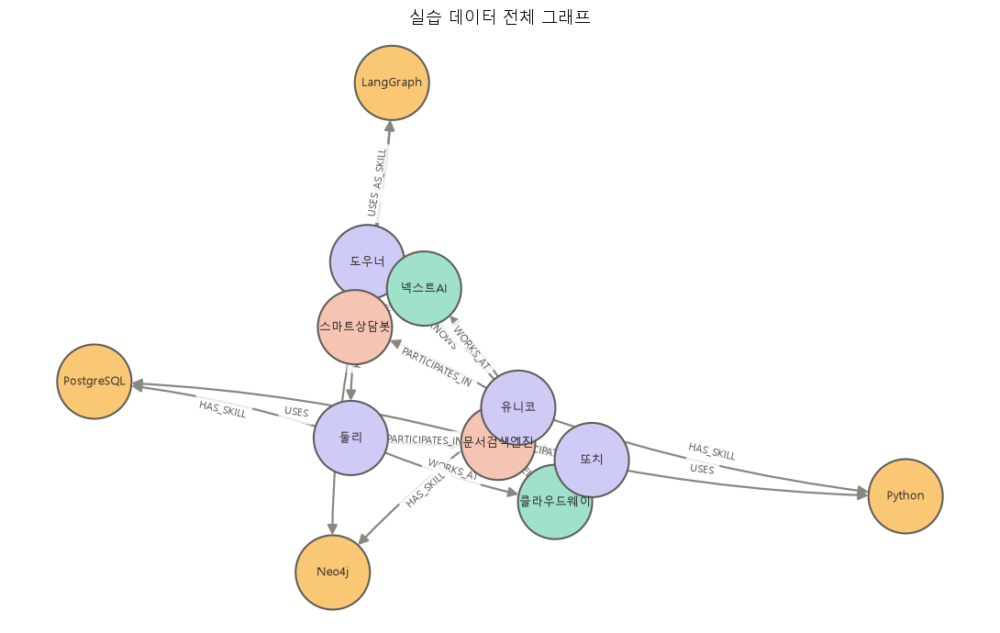

In [13]:
draw("MATCH (n)-[r]->(m) RETURN n, r, m", title="실습 데이터 전체 그래프")

In [14]:
# 라벨별 노드 수와 관계 타입별 개수
display(run("MATCH (n) RETURN labels(n)[0] AS 라벨, count(*) AS 개수 ORDER BY 개수 DESC"))
display(run("MATCH ()-[r]->() RETURN type(r) AS 관계, count(*) AS 개수 ORDER BY 개수 DESC"))

,라벨,개수
0,Person,4
1,Technology,4
2,Company,2
3,Project,2


,관계,개수
0,USES,4
1,WORKS_AT,4
2,HAS_SKILL,4
3,PARTICIPATES_IN,4
4,KNOWS,2
5,DEVELOPS,2


### 4단계. 패턴으로 찾기 — MATCH 기본

`MATCH` 뒤에 **찾고 싶은 모양을 그림처럼** 적으면, 그 모양과 일치하는 데이터를 모두 찾아 줍니다.

| SQL | Cypher |
|---|---|
| `SELECT ... FROM person JOIN works_at ... JOIN company ...` | `MATCH (p:Person)-[:WORKS_AT]->(c:Company)` |

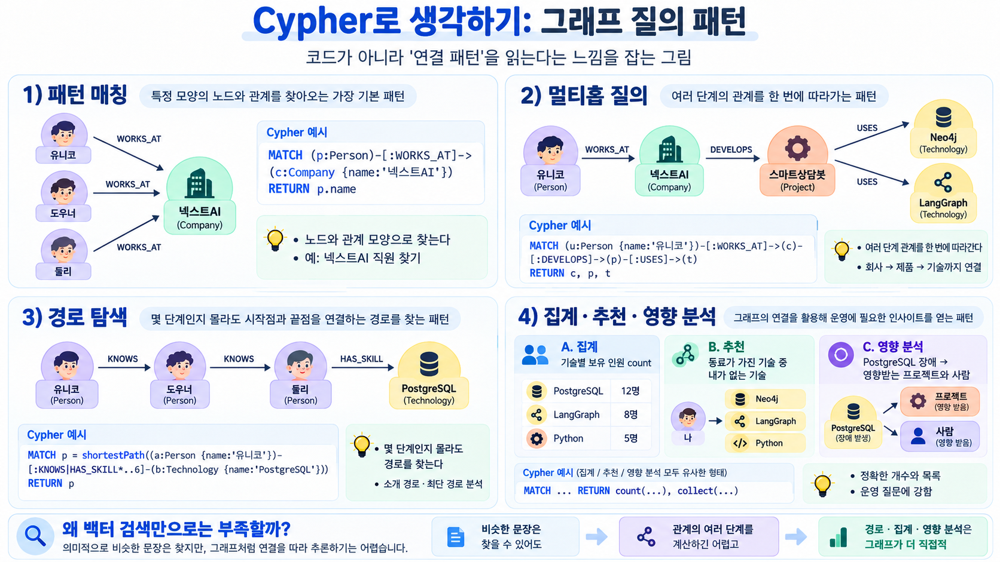

In [15]:
# ① 넥스트AI 직원 — 관계의 속성(since)도 함께 꺼낼 수 있다
run('''
MATCH (p:Person)-[r:WORKS_AT]->(c:Company {name: $company})
RETURN p.name AS 이름, p.role AS 직무, r.since AS 입사연도
ORDER BY r.since
''', company="넥스트AI")

,이름,직무,입사연도
0,유니코,데이터 엔지니어,2023
1,도우너,AI 엔지니어,2024


In [16]:
# ② 방향 없이 찾기: KNOWS 는 '서로 아는 사이'라서 방향을 무시하고 찾는 것이 자연스럽다
display(run("MATCH (a:Person {name: '도우너'})-[:KNOWS]->(b) RETURN b.name AS `도우너가 아는 사람(→ 방향만)`"))
display(run("MATCH (a:Person {name: '도우너'})-[:KNOWS]-(b)  RETURN b.name AS `도우너와 아는 사이(방향 무시)`"))

,도우너가 아는 사람(→ 방향만)
0,둘리


,도우너와 아는 사이(방향 무시)
0,유니코
1,둘리


In [17]:
# ③ 같은 회사 동료 찾기 — 두 화살표가 한 노드(c)로 모이는 패턴
run('''
MATCH (a:Person)-[:WORKS_AT]->(c:Company)<-[:WORKS_AT]-(b:Person)
WHERE a.name < b.name                          // (A,B)와 (B,A) 중복 제거
RETURN c.name AS 회사, a.name AS 동료1, b.name AS 동료2
''')

,회사,동료1,동료2
0,클라우드웨이,둘리,또치
1,넥스트AI,도우너,유니코


### 5단계. ⭐ 장점 ① 멀티홉 질문 — 여러 단계 관계를 한 번에

**홉(hop)** = 관계 하나를 따라 옆 노드로 한 칸 이동하는 것.

> ❓ "유니코가 일하는 회사의 제품은 어떤 기술을 쓰나요?"

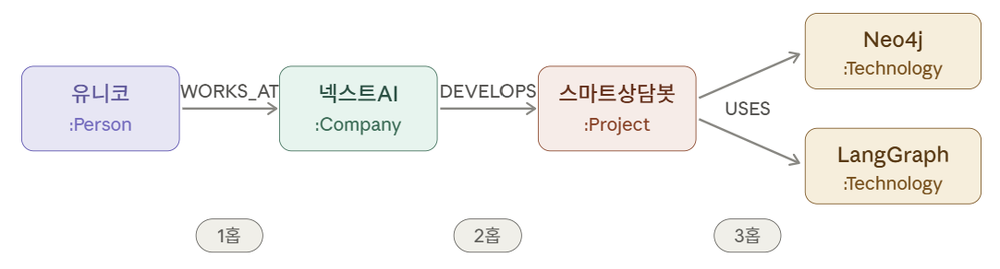

벡터 RAG에서는 이 사실들이 서로 다른 청크에 흩어져 있으면 마지막 사실을 놓치기 쉽습니다. 그래프에서는 **관계를 따라 그대로 이동**합니다.

In [18]:
run('''
MATCH (p:Person {name: '유니코'})-[:WORKS_AT]->(c:Company)
      -[:DEVELOPS]->(pr:Project)-[:USES]->(t:Technology)
RETURN c.name AS 회사, pr.name AS 프로젝트, collect(t.name) AS 기술
''')

,회사,프로젝트,기술
0,넥스트AI,스마트상담봇,"[LangGraph, Neo4j]"


**📝 정리** — 회사 → 프로젝트 → 기술 3홉을 화살표 3개로 썼다. SQL이면 JOIN 6개가 필요하다.

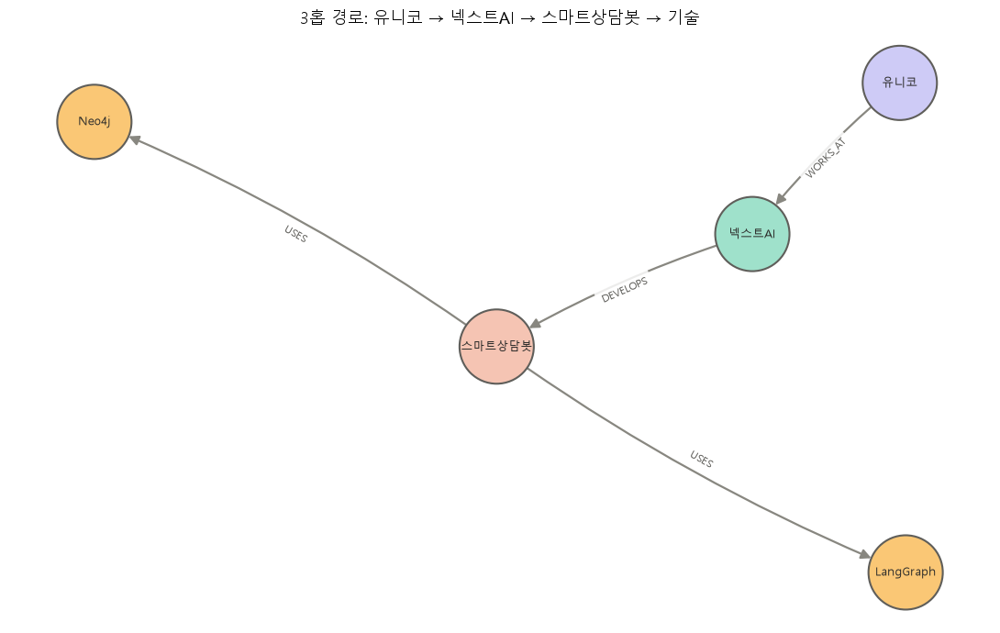

In [19]:
draw('''
MATCH path = (:Person {name: '유니코'})-[:WORKS_AT]->(:Company)-[:DEVELOPS]->(:Project)-[:USES]->(:Technology)
RETURN path
''', title="3홉 경로: 유니코 → 넥스트AI → 스마트상담봇 → 기술")

#### 같은 질문을 SQL로 쓴다면?
```sql
SELECT c.name, pr.name, t.name
FROM   person p
JOIN   works_at   w  ON w.person_id  = p.id
JOIN   company    c  ON c.id         = w.company_id
JOIN   develops   d  ON d.company_id = c.id
JOIN   project    pr ON pr.id        = d.project_id
JOIN   uses       u  ON u.project_id = pr.id
JOIN   technology t  ON t.id         = u.tech_id
WHERE  p.name = '유니코';
```
**JOIN 6개** 대 **화살표 3개**. 단계가 늘수록 SQL은 JOIN이 두 개씩 늘어나지만, Cypher는 화살표 하나만 더 그리면 됩니다.

### 6단계. ⭐ 장점 ② 경로 탐색 — 몇 단계인지 몰라도 찾기

관계형 DB에서 "몇 단계 떨어져 있는지 모르는" 연결을 찾으려면 재귀 CTE(`WITH RECURSIVE`)가 필요합니다. 그래프에서는 **가변 길이 패턴**과 **최단 경로** 함수로 간단히 찾습니다.

| 표기 | 의미 |
|---|---|
| `-[:KNOWS]-{2}` | KNOWS 관계를 정확히 2번 (수량 경로 패턴, 권장 문법) |
| `-[:KNOWS*2]-` | 같은 의미의 예전 문법 |
| `-[*..6]-` | 아무 관계나 1~6번 (상한을 꼭 두세요) |

In [20]:
# 친구의 친구: 유니코 -KNOWS- 도우너 -KNOWS- 둘리
run('''
MATCH (me:Person {name: '유니코'})-[:KNOWS]-{2}(fof:Person)
WHERE fof <> me
RETURN DISTINCT fof.name AS 친구의친구
''')

,친구의친구
0,둘리


In [21]:
# 최단 경로: 유니코와 PostgreSQL 은 몇 단계로 연결되어 있을까? (관계 종류 제한 없음)
# allShortestPaths: 길이가 같은 최단 경로를 '모두' 찾는다
run('''
MATCH p = allShortestPaths(
  (a:Person {name: '유니코'})-[*..6]-(b:Technology {name: 'PostgreSQL'})
)
RETURN [n IN nodes(p) | n.name]         AS 경로,
       [r IN relationships(p) | type(r)] AS 관계,
       length(p)                         AS 홉수
''')

,경로,관계,홉수
0,"[유니코, 도우너, 둘리, PostgreSQL]","[KNOWS, KNOWS, HAS_SKILL]",3
1,"[유니코, Python, 문서검색엔진, PostgreSQL]","[HAS_SKILL, USES, USES]",3


**📝 정리** — 길이 3인 최단 경로가 **2개**(도우너 → 둘리 경유 등). `allShortestPaths`는 같은 길이를 모두 찾는다.

최단 경로가 **두 개**(3홉) 나옵니다.

| 경로 | 의미 |
|---|---|
| 유니코 → 도우너 → 둘리 → PostgreSQL | 사람을 통해 PostgreSQL 전문가에게 닿는 **인맥 경로** |
| 유니코 → Python ← 문서검색엔진 → PostgreSQL | 같은 기술(Python)을 쓰는 프로젝트를 거치는 **기술 경로** |

어떤 경로가 의미 있는지는 질문에 달려 있습니다. "PostgreSQL 전문가를 **소개받으려면**?"이라는 질문이라면 사람 관계만 따라가야 합니다. 이럴 때 **관계 타입을 지정**합니다.

In [22]:
# 소개 경로: 사람 관계(KNOWS)와 기술 보유(HAS_SKILL)만 따라간다
run('''
MATCH p = shortestPath(
  (a:Person {name: '유니코'})-[:KNOWS|HAS_SKILL*..6]-(b:Technology {name: 'PostgreSQL'})
)
RETURN [n IN nodes(p) | n.name]         AS 경로,
       [r IN relationships(p) | type(r)] AS 관계,
       length(p)                         AS 홉수
''')

,경로,관계,홉수
0,"[유니코, 도우너, 둘리, PostgreSQL]","[KNOWS, KNOWS, HAS_SKILL]",3


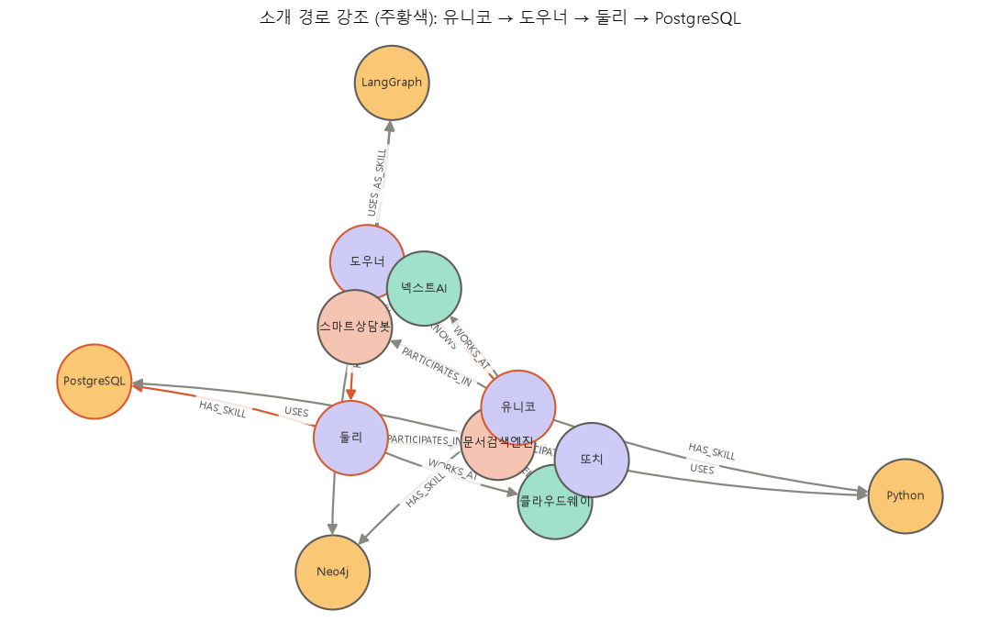

In [23]:
draw('''
MATCH (n)-[r]->(m) RETURN n, r, m       // 전체 그래프를 그리고, 소개 경로 위 노드만 강조
''', title="소개 경로 강조 (주황색): 유니코 → 도우너 → 둘리 → PostgreSQL",
     highlight=["유니코", "도우너", "둘리", "PostgreSQL"])

> 💡 그림에서 주황색 테두리·선이 소개 경로입니다. "유니코가 PostgreSQL 전문가를 소개받으려면 누구를 거쳐야 할까?" 같은 **인맥·의존성·영향 경로** 질문에 바로 쓸 수 있습니다.
> 관계형 DB라면 경로 길이를 모르는 이런 질문을 재귀 CTE로 써야 합니다.

### 7단계. ⭐ 장점 ③ 정확한 집계 · 추천 · 영향 분석

벡터 RAG는 Top-k 청크만 보기 때문에 **"모두", "몇 명"** 에 정확히 답하기 어렵습니다. 그래프는 조건에 맞는 노드를 **빠짐없이** 세고 나열합니다.

In [24]:
# ① 집계: 기술별 보유 인원
run('''
MATCH (p:Person)-[:HAS_SKILL]->(t:Technology)
RETURN t.name AS 기술, count(p) AS 인원, collect(p.name) AS 사람들
ORDER BY 인원 DESC, 기술
''')

,기술,인원,사람들
0,LangGraph,1,[도우너]
1,Neo4j,1,[유니코]
2,PostgreSQL,1,[둘리]
3,Python,1,[유니코]


In [25]:
# ② 추천: 유니코의 동료가 가진 기술 중 유니코에게 없는 것
run('''
MATCH (me:Person {name: '유니코'})-[:WORKS_AT]->(c:Company)<-[:WORKS_AT]-(col:Person),
      (col)-[:HAS_SKILL]->(t:Technology)
WHERE NOT (me)-[:HAS_SKILL]->(t)
RETURN t.name AS 추천기술, collect(col.name) AS 가진동료
''')

,추천기술,가진동료
0,LangGraph,[도우너]


In [26]:
# ③ 영향 분석: PostgreSQL 에 장애가 나면 영향받는 프로젝트와 사람
run('''
MATCH (t:Technology {name: 'PostgreSQL'})<-[:USES]-(pr:Project)<-[:PARTICIPATES_IN]-(p:Person)
RETURN pr.name AS 프로젝트, collect(p.name) AS 영향받는사람
''')

,프로젝트,영향받는사람
0,문서검색엔진,"[또치, 둘리]"


**📝 정리** — PostgreSQL 장애 → 문서검색엔진 → [또치, 둘리]. 직접 쓴 Cypher는 빠짐없이 찾는다(아래 GraphRAG 비교 ④와 대조).

In [27]:
# ④ WITH 로 단계 나누기: 직원이 2명 이상인 회사가 개발하는 프로젝트
run('''
MATCH (c:Company)<-[:WORKS_AT]-(p:Person)
WITH c, count(p) AS 직원수              // 1단계 결과를 다음 단계로 넘김
WHERE 직원수 >= 2
MATCH (c)-[:DEVELOPS]->(pr:Project)
RETURN c.name AS 회사, 직원수, collect(pr.name) AS 프로젝트
''')

,회사,직원수,프로젝트
0,넥스트AI,2,[스마트상담봇]
1,클라우드웨이,2,[문서검색엔진]


### 8단계. ⭐ 장점 ④ 유연한 스키마 — 테이블 변경 없이 확장

관계형 DB에서 "멘토 관계"나 "자격증"을 추가하려면 새 테이블과 외래 키를 만들어야 합니다. 그래프에서는 **새 라벨과 관계를 바로** 추가하면 됩니다.

또 Python에서 여러 건을 넣을 때는 한 건씩 보내지 말고, **리스트를 한 번에 보내 `UNWIND`로 펼치는** 방식이 빠릅니다. (교안 5.2절)

In [28]:
# 새 직원 2명을 한 번에 적재 (UNWIND 배치)
new_people = [
    {"name": "마이콜", "role": "프론트엔드 개발자", "company": "넥스트AI",   "skills": ["React", "Python"]},
    {"name": "희동이", "role": "인턴",              "company": "넥스트AI",   "skills": ["Neo4j"]},
]

summary = driver.execute_query('''
UNWIND $rows AS row
MERGE (p:Person {name: row.name})
SET   p.role = row.role
MERGE (c:Company {name: row.company})
MERGE (p)-[:WORKS_AT]->(c)
WITH  p, row
UNWIND row.skills AS skill
MERGE (t:Technology {name: skill})
MERGE (p)-[:HAS_SKILL]->(t)
''', {"rows": new_people}, database_="neo4j").summary
print(summary.counters)

SummaryCounters{labels_added: 3, relationships_created: 5, nodes_created: 3, properties_set: 5, contains_updates: True, contains_system_updates: False}


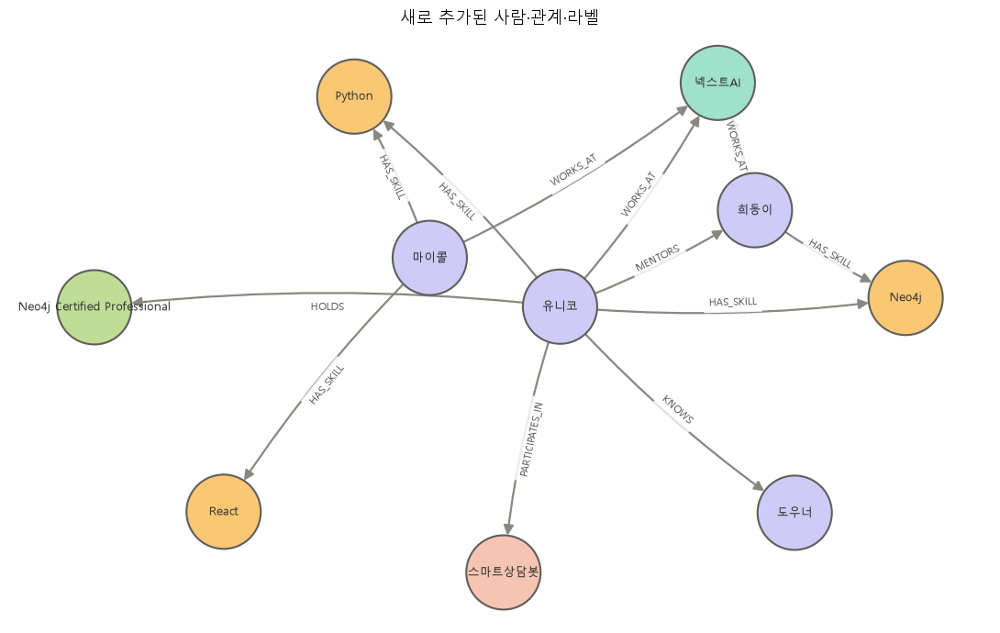

In [29]:
# 처음 보는 라벨(Certificate)과 관계(MENTORS, HOLDS)를 테이블 변경 없이 바로 추가
run('''
MATCH (u:Person {name: '유니코'}), (h:Person {name: '희동이'})
MERGE (u)-[:MENTORS {since: 2026}]->(h)
MERGE (cert:Certificate {name: 'Neo4j Certified Professional'})
MERGE (u)-[:HOLDS]->(cert)
''')

draw('''
MATCH (n)-[r]->(m)
WHERE n.name IN ['유니코', '희동이', '마이콜'] OR m.name IN ['유니코', '희동이', '마이콜']
RETURN n, r, m
''', title="새로 추가된 사람·관계·라벨")

In [30]:
# 새로 생긴 연결 덕분에 바로 가능한 질문: "Neo4j를 다룰 줄 아는 사람을 모두"
run('''
MATCH (p:Person)-[:HAS_SKILL]->(:Technology {name: 'Neo4j'})
OPTIONAL MATCH (mentor:Person)-[:MENTORS]->(p)
RETURN p.name AS 이름, p.role AS 직무, mentor.name AS 멘토
''')

,이름,직무,멘토
0,희동이,인턴,유니코
1,유니코,데이터 엔지니어,NaN


### 9단계. 인덱스와 실행 계획

그래프 탐색은 보통 **시작 노드 하나를 찾은 뒤** 관계를 따라갑니다. 그래서 시작점이 되는 속성(이름 등)에 인덱스가 있어야 빠릅니다. 3단계에서 만든 유일성 제약조건이 이미 인덱스를 만들어 두었습니다.

| 종류 | 용도 |
|---|---|
| 유일성 제약조건 | 중복 방지 + 자동 인덱스 |
| 범위(Range) 인덱스 | `=`, `>`, `<` 조건 검색 |
| 전문(Full-text) 인덱스 | 키워드 검색 |
| 벡터 인덱스 | 임베딩 유사도 검색 (12단계) |

In [31]:
run("CREATE INDEX project_year IF NOT EXISTS FOR (n:Project) ON (n.startYear)")
run("SHOW INDEXES YIELD name, type, labelsOrTypes, properties, state")

,name,type,labelsOrTypes,properties,state
0,company_name,RANGE,[Company],[name],ONLINE
1,index_1b9dcc97,LOOKUP,None,None,ONLINE
2,index_460996c0,LOOKUP,None,None,ONLINE
3,person_name,RANGE,[Person],[name],ONLINE
4,project_name,RANGE,[Project],[name],ONLINE
5,project_year,RANGE,[Project],[startYear],POPULATING
6,technology_name,RANGE,[Technology],[name],ONLINE


In [32]:
# PROFILE: 쿼리를 실행하면서 단계별 비용을 보여 준다
# 'NodeUniqueIndexSeek' 가 보이면 인덱스로 시작 노드를 바로 찾았다는 뜻
summary = driver.execute_query(
    "PROFILE MATCH (p:Person {name: '유니코'})-[:WORKS_AT]->(c) RETURN c.name",
    database_="neo4j",
).summary


def print_plan(plan, depth=0):
    # 실행 계획 트리를 들여쓰기로 출력
    print("  " * depth + f"▸ {plan['operatorType']}  (rows={plan.get('rows')}, dbHits={plan.get('dbHits')})")
    for child in plan.get("children", []):
        print_plan(child, depth + 1)


print_plan(summary.profile)

▸ ProduceResults@neo4j  (rows=1, dbHits=0)
  ▸ Projection@neo4j  (rows=1, dbHits=1)
    ▸ Expand(All)@neo4j  (rows=1, dbHits=8)
      ▸ NodeUniqueIndexSeek@neo4j  (rows=1, dbHits=2)


**📝 정리** — `NodeUniqueIndexSeek`: 유일성 제약이 만든 인덱스로 시작 노드를 바로 찾았다.

### 1부 정리

| 확인한 장점 | 단계 | 핵심 문법 |
|---|---|---|
| 관계를 그림처럼 질의 | 4 | `MATCH (a)-[:REL]->(b)` |
| 멀티홉을 짧은 쿼리로 | 5 | 화살표를 이어 쓰기 |
| 깊이를 몰라도 경로 탐색 | 6 | `-{2}`, `shortestPath(...)` |
| 정확한 집계·추천·영향 분석 | 7 | `count`, `collect`, `WHERE NOT (...)`, `WITH` |
| 테이블 변경 없이 확장 | 8 | 새 라벨·관계 바로 `MERGE`, `UNWIND` 배치 |

---
## 2부. GraphRAG — 문서를 지식 그래프로 만들고, 관계로 답하기

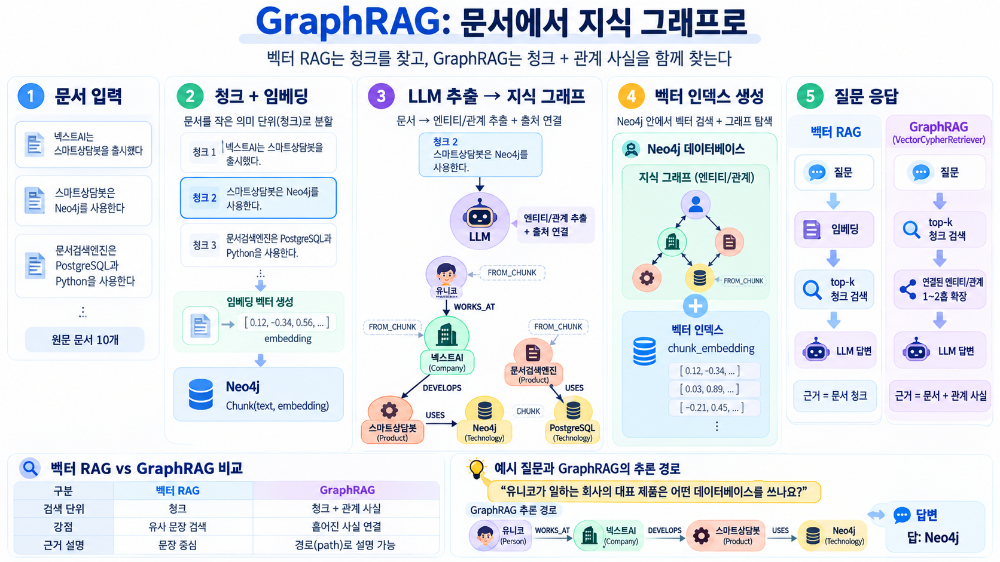

### 10단계. GraphRAG 준비

1부에서는 사람이 직접 그래프를 만들었습니다. 2부에서는 **LLM이 문서를 읽고 그래프를 만들게** 한 뒤, 그 그래프로 RAG를 합니다.

#### 실습 문서
회사·제품 소개 4개, 직원 소개 6개로 모두 **10개의 짧은 문서**입니다. 일부러 **한 문서에 한 가지 주제**만 담았습니다. 실제 사내 문서처럼 사실이 여러 문서에 흩어져 있어야 벡터 RAG와 GraphRAG의 차이가 잘 드러나기 때문입니다.

> ⚠️ Community Edition은 데이터베이스를 하나만 쓸 수 있으므로, 1부 데이터와 제약조건을 지우고 시작합니다.
> 자동 추출 과정에서 같은 이름의 노드가 잠시 여러 개 생겼다가 병합되기 때문에, 1부의 유일성 제약조건이 남아 있으면 오류가 납니다.

In [33]:
# 1부 데이터·제약조건·인덱스 정리
run("MATCH (n) DETACH DELETE n")
for row in run("SHOW CONSTRAINTS YIELD name").itertuples():
    run(f"DROP CONSTRAINT {row.name} IF EXISTS")
run("DROP INDEX project_year IF EXISTS")
run("MATCH (n) RETURN count(n) AS 남은노드수")

,남은노드수
0,0


In [34]:
DOCUMENTS = [
    # 회사·제품 소개
    "넥스트AI는 2019년에 설립된 AI 상담 솔루션 회사다. 본사는 서울 성수동에 있다. "
    "넥스트AI는 2026년에 대표 제품인 스마트상담봇을 출시했다.",
    "스마트상담봇은 상담 이력과 고객 관계 데이터를 Neo4j 그래프 데이터베이스에 저장한다. "
    "상담 흐름 제어에는 LangGraph를 사용한다.",
    "클라우드웨이는 기업용 클라우드 서비스를 제공하는 회사다. "
    "클라우드웨이는 사내 문서를 빠르게 찾아 주는 문서검색엔진을 개발했다.",
    "문서검색엔진은 PostgreSQL과 pgvector로 문서 임베딩을 저장하고 검색한다. "
    "문서검색엔진의 백엔드는 Python으로 작성되었다.",
    # 직원 소개 (한 사람에 한 문서)
    "유니코는 넥스트AI의 데이터 엔지니어다. 유니코는 Python과 Neo4j를 잘 다루며, "
    "스마트상담봇 프로젝트에 참여해 데이터 파이프라인을 만들었다.",
    "도우너는 넥스트AI의 AI 엔지니어로 LangGraph 전문가다. 도우너도 스마트상담봇 프로젝트에 참여했다. "
    "도우너는 유니코, 둘리와 잘 알고 지낸다.",
    "마이콜은 넥스트AI에서 프론트엔드 개발자로 일한다. 마이콜은 React를 주로 사용하며 "
    "스마트상담봇 프로젝트에서 상담원 화면을 만들었다.",
    "희동이는 넥스트AI의 인턴이다. 희동이는 요즘 Neo4j를 공부하고 있다.",
    "둘리는 클라우드웨이의 백엔드 개발자이며 PostgreSQL에 능숙하다. 둘리는 문서검색엔진 프로젝트를 이끌고 있다.",
    "또치는 클라우드웨이의 PM이다. 또치는 문서검색엔진 프로젝트에 참여하고 있다.",
]

for i, d in enumerate(DOCUMENTS, 1):
    print(f"[문서 {i:2}] {d}")

[문서  1] 넥스트AI는 2019년에 설립된 AI 상담 솔루션 회사다. 본사는 서울 성수동에 있다. 넥스트AI는 2026년에 대표 제품인 스마트상담봇을 출시했다.
[문서  2] 스마트상담봇은 상담 이력과 고객 관계 데이터를 Neo4j 그래프 데이터베이스에 저장한다. 상담 흐름 제어에는 LangGraph를 사용한다.
[문서  3] 클라우드웨이는 기업용 클라우드 서비스를 제공하는 회사다. 클라우드웨이는 사내 문서를 빠르게 찾아 주는 문서검색엔진을 개발했다.
[문서  4] 문서검색엔진은 PostgreSQL과 pgvector로 문서 임베딩을 저장하고 검색한다. 문서검색엔진의 백엔드는 Python으로 작성되었다.
[문서  5] 유니코는 넥스트AI의 데이터 엔지니어다. 유니코는 Python과 Neo4j를 잘 다루며, 스마트상담봇 프로젝트에 참여해 데이터 파이프라인을 만들었다.
[문서  6] 도우너는 넥스트AI의 AI 엔지니어로 LangGraph 전문가다. 도우너도 스마트상담봇 프로젝트에 참여했다. 도우너는 유니코, 둘리와 잘 알고 지낸다.
[문서  7] 마이콜은 넥스트AI에서 프론트엔드 개발자로 일한다. 마이콜은 React를 주로 사용하며 스마트상담봇 프로젝트에서 상담원 화면을 만들었다.
[문서  8] 희동이는 넥스트AI의 인턴이다. 희동이는 요즘 Neo4j를 공부하고 있다.
[문서  9] 둘리는 클라우드웨이의 백엔드 개발자이며 PostgreSQL에 능숙하다. 둘리는 문서검색엔진 프로젝트를 이끌고 있다.
[문서 10] 또치는 클라우드웨이의 PM이다. 또치는 문서검색엔진 프로젝트에 참여하고 있다.


In [35]:
from neo4j_graphrag.llm import OpenAILLM
from neo4j_graphrag.embeddings import OpenAIEmbeddings

# 지식 그래프 추출용 LLM — JSON 형식 + temperature 0 으로 결과를 안정적으로
extract_llm = OpenAILLM(
    model_name="gpt-4o-mini",
    model_params={"response_format": {"type": "json_object"}, "temperature": 0},
)
# 답변 생성용 LLM
answer_llm = OpenAILLM(model_name="gpt-4o-mini", model_params={"temperature": 0})

# 임베딩 모델 (1536차원) — 기본값이 예전 모델이므로 반드시 지정
embedder = OpenAIEmbeddings(model="text-embedding-3-small")

print("임베딩 차원:", len(embedder.embed_query("안녕하세요")))

임베딩 차원: 1536


### 11단계. 문서 → 지식 그래프 (SimpleKGPipeline)

`neo4j-graphrag`의 `SimpleKGPipeline`은 아래 과정을 한 번에 처리합니다. (교안 5.3~5.4절)

```
문서 → 텍스트 분할(Chunk) → 청크 임베딩 → LLM 엔티티·관계 추출 → 엔티티 해소(중복 병합) → Neo4j 저장
```

#### 스키마가 품질의 절반
스키마 없이 추출하면 같은 의미의 관계가 `WORKS_AT`, `EMPLOYED_BY`, `일한다`처럼 제각각 생깁니다. 1부와 같은 라벨·관계를 스키마로 지정해 **허용된 모양으로만** 추출하게 합니다.

> 📌 `neo4j-graphrag` 1.22.0 기준으로 스키마는 `schema=` 인자 하나로 넘깁니다. 예전 자료의 `entities`, `relations`, `potential_schema`, `from_pdf`는 사용 중단 예정입니다.

In [36]:
from neo4j_graphrag.components.text_splitters.fixed_size_splitter import FixedSizeSplitter
from neo4j_graphrag.experimental.pipeline.kg_builder import SimpleKGPipeline

SCHEMA = {
    "node_types": [
        {"label": "Person",
         "description": "사람. 이름은 문서에 쓰인 그대로 쓴다 (예: '희동이는' → '희동이', '마이콜은' → '마이콜')",
         "properties": [{"name": "name", "type": "STRING"}, {"name": "role", "type": "STRING"}]},
        {"label": "Company", "description": "회사"},
        {"label": "Project", "description": "회사가 개발하는 서비스나 제품 (예: 스마트상담봇, 문서검색엔진)"},
        {"label": "Technology",
         "description": "소프트웨어·데이터베이스·프레임워크·언어. 이름은 제품명만 짧게 (예: 'Neo4j 그래프 데이터베이스' → 'Neo4j')"},
    ],
    "relationship_types": [
        {"label": "WORKS_AT", "description": "사람이 회사에서 일한다"},
        {"label": "DEVELOPS", "description": "회사가 프로젝트(제품)를 개발·출시했다"},
        {"label": "USES",
         "description": "프로젝트(제품)가 내부적으로 쓰는 기술. '~에 저장한다', '~로 제어한다', '~로 작성되었다'도 USES다. "
                        "주어가 사람이면 USES가 아니라 HAS_SKILL이다"},
        {"label": "HAS_SKILL",
         "description": "사람이 다룰 줄 알거나 주로 사용하거나 공부하는 기술. 예: '마이콜은 React를 주로 사용한다' → 마이콜 HAS_SKILL React"},
        {"label": "PARTICIPATES_IN", "description": "사람이 프로젝트에 참여했거나 이끈다"},
        {"label": "KNOWS", "description": "사람과 사람이 서로 아는 사이"},
    ],
    "patterns": [
        ("Person", "WORKS_AT", "Company"),
        ("Company", "DEVELOPS", "Project"),
        ("Project", "USES", "Technology"),
        ("Person", "HAS_SKILL", "Technology"),
        ("Person", "PARTICIPATES_IN", "Project"),
        ("Person", "KNOWS", "Person"),
    ],
}

kg_builder = SimpleKGPipeline(
    llm=extract_llm,
    driver=driver,
    embedder=embedder,
    schema=SCHEMA,
    text_splitter=FixedSizeSplitter(chunk_size=300, chunk_overlap=30),   # 짧은 문서 → 문서 하나가 청크 하나
    from_file=False,                     # 텍스트를 직접 넣음 (True 면 PDF·마크다운 파일 경로)
    perform_entity_resolution=True,      # 같은 라벨·같은 이름의 엔티티를 하나로 병합
)

In [37]:
# 문서 10개를 차례로 그래프로 변환 (주피터에서는 await 로 비동기 함수를 바로 실행)
for i, doc in enumerate(DOCUMENTS, 1):
    await kg_builder.run_async(text=doc)
    print(f"✅ 문서 {i:2} 처리 완료")

✅ 문서  1 처리 완료
✅ 문서  2 처리 완료
✅ 문서  3 처리 완료
✅ 문서  4 처리 완료
✅ 문서  5 처리 완료
✅ 문서  6 처리 완료
✅ 문서  7 처리 완료
✅ 문서  8 처리 완료
✅ 문서  9 처리 완료
✅ 문서 10 처리 완료


> 💡 **.py 스크립트에서 실행할 때는** `await` 대신 `asyncio.run(kg_builder.run_async(text=doc))`를 사용하세요.
>
> ⚠️ **추출을 다시 하고 싶을 때**는 이 셀만 다시 실행하지 말고 **10단계의 정리 셀부터** 실행하세요. 그래프가 남아 있는 상태에서 다시 실행하면 같은 문장의 청크가 두 번 저장되어, 벡터 검색 결과에 같은 문장이 중복으로 나옵니다.

#### 결과 살펴보기
파이프라인이 만든 그래프는 두 가지 층입니다. (교안 2.4절, 그림 5-1)

| 층 | 노드 | 하는 일 |
|---|---|---|
| **어휘 그래프** | `Chunk` (text, embedding 속성) | 원문 보관, 벡터 검색의 입구 |
| **엔티티 그래프** | `Person`, `Company` … (+ 내부 라벨 `__Entity__`) | 추출된 지식 |

두 가지 층은 `(엔티티)-[:FROM_CHUNK]->(청크)`로 연결되어 **"이 사실은 어느 문장에서 나왔나"** 를 언제든 추적할 수 있습니다.

In [38]:
display(run('''
MATCH (n)
RETURN [l IN labels(n) WHERE NOT l STARTS WITH '__'][0] AS 라벨, count(*) AS 개수
ORDER BY 개수 DESC
'''))
display(run('''
MATCH (:__Entity__)-[r]->(:__Entity__)
RETURN type(r) AS 관계, count(*) AS 개수 ORDER BY 개수 DESC
'''))

,라벨,개수
0,Document,10
1,Chunk,10
2,Person,6
3,Technology,6
4,Project,2
5,Company,2


,관계,개수
0,WORKS_AT,6
1,PARTICIPATES_IN,5
2,HAS_SKILL,5
3,USES,5
4,DEVELOPS,2
5,KNOWS,2


**📝 정리** — 어휘 그래프(Document 10, Chunk 10) + 지식 그래프(Person 6, Technology 6, Project 2, Company 2).

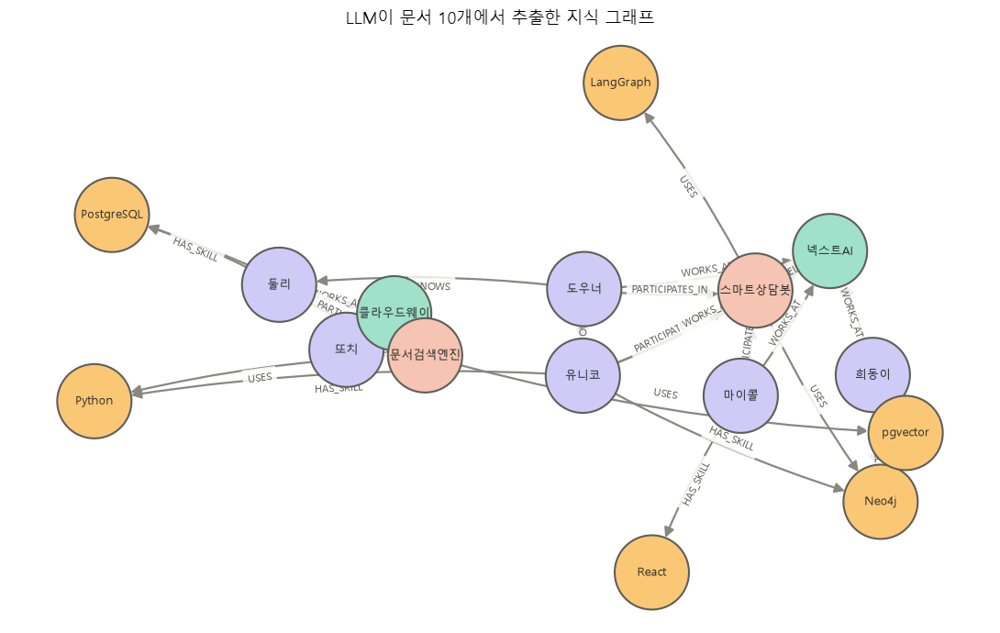

In [39]:
draw("MATCH (a:__Entity__)-[r]->(b:__Entity__) RETURN a, r, b",
     title="LLM이 문서 10개에서 추출한 지식 그래프")

In [40]:
# 근거 추적: '유니코'에 관한 사실은 어느 청크에서 나왔을까?
run('''
MATCH (e:__Entity__ {name: '유니코'})-[:FROM_CHUNK]->(c:Chunk)
RETURN e.name AS 엔티티, c.text AS 출처문장
''')

,엔티티,출처문장
0,유니코,유니코는 넥스트AI의 데이터 엔지니어다. 유니코는 Python과 Neo4j를 잘 다...
1,유니코,도우너는 넥스트AI의 AI 엔지니어로 LangGraph 전문가다. 도우너도 스마트상...


> 💡 **추출 결과는 실행마다 조금씩 다를 수 있습니다.** 이름이 '넥스트 AI'처럼 다르게 추출되었거나 관계가 빠졌다면, 스키마의 `description`을 보강하거나 문서 문장을 명확하게 다듬는 것이 효과적입니다.

#### ✅ 추출 품질 점검 — 다음 단계로 가기 전에 꼭 확인!
GraphRAG는 **그래프에 있는 사실을 그대로 믿고** 답합니다. 그래프가 틀리면 **틀린 답을 자신 있게** 합니다. 그래서 추출이 끝나면 핵심 관계가 제대로 들어갔는지 먼저 확인합니다.

| 확인 항목 | 기대 결과 |
|---|---|
| 프로젝트의 사용 기술 (USES) | 스마트상담봇 → Neo4j, LangGraph / 문서검색엔진 → PostgreSQL, pgvector, Python |
| 사람 이름과 회사 | 6명 (희동이는 '희동'이 아니라 **'희동이'**), React는 마이콜의 기술(HAS_SKILL) |

결과가 다르면 11단계 `SCHEMA`의 `description`을 보강하거나, 추출용 `extract_llm`만 더 강한 모델로 바꿔 다시 추출합니다.

In [41]:
display(run('''
MATCH (p:Project)-[:USES]->(t)
RETURN p.name AS 프로젝트, collect(t.name) AS 사용기술
'''))
display(run('''
MATCH (p:Person)
OPTIONAL MATCH (p)-[:WORKS_AT]->(c)
OPTIONAL MATCH (p)-[:HAS_SKILL]->(t)
RETURN p.name AS 이름, p.role AS 직무, c.name AS 회사, collect(t.name) AS 보유기술
ORDER BY 회사, 이름
'''))

,프로젝트,사용기술
0,스마트상담봇,"[Neo4j, LangGraph]"
1,문서검색엔진,"[PostgreSQL, pgvector, Python]"


,이름,직무,회사,보유기술
0,도우너,None,넥스트AI,[]
1,마이콜,None,넥스트AI,[React]
2,유니코,None,넥스트AI,"[Neo4j, Python]"
3,희동이,None,넥스트AI,[Neo4j]
4,둘리,None,클라우드웨이,[PostgreSQL]
5,또치,None,클라우드웨이,[]


**📝 정리** — 품질 점검: 스키마에 넣은 `role`이 **6명 모두 None**, 도우너·또치는 보유 기술이 비어 있다. GraphRAG는 그래프의 사실을 그대로 믿으므로 추출 결과를 먼저 확인해야 한다.

### 12단계. 벡터 인덱스와 SEARCH 절 — pgvector에서 하던 일을 Neo4j에서

GraphRAG도 첫 단계는 벡터 검색입니다. 질문과 관련된 **청크(입구)** 를 찾아야 그래프 탐색을 시작할 수 있기 때문입니다. Neo4j는 벡터 인덱스를 내장하고 있어 **별도의 벡터 DB가 필요 없습니다.**

| 작업 | PostgreSQL + pgvector | Neo4j |
|---|---|---|
| 인덱스 | `CREATE INDEX ... USING hnsw (embedding vector_cosine_ops)` | `CREATE VECTOR INDEX ... OPTIONS {indexConfig: ...}` |
| 검색 | `ORDER BY embedding <=> $q LIMIT 3` | `SEARCH c IN (VECTOR INDEX ... FOR $q LIMIT 3)` |
| 검색 후 관계 활용 | 다른 테이블과 JOIN | **같은 쿼리에서 바로 MATCH** |

In [42]:
run('''
CREATE VECTOR INDEX chunk_embedding IF NOT EXISTS
FOR (c:Chunk) ON (c.embedding)
OPTIONS { indexConfig: {
  `vector.dimensions`: 1536,
  `vector.similarity_function`: 'cosine'
}}
''')

# 인덱스가 ONLINE 이 될 때까지 기다림
run("CALL db.awaitIndex('chunk_embedding', 60)")
run("SHOW VECTOR INDEXES YIELD name, state, labelsOrTypes, properties")

,name,state,labelsOrTypes,properties
0,chunk_embedding,ONLINE,[Chunk],[embedding]


#### SEARCH 절로 벡터 검색 (Neo4j 2026.01+)
Neo4j 2026.02부터 정식 기능이 된 Cypher 문법입니다. `CYPHER 25`를 앞에 붙여 Cypher 25 문법임을 명시합니다.

In [43]:
def vector_search(question: str, k: int = 3) -> pd.DataFrame:
    # 질문과 가장 비슷한 청크 k개를 SEARCH 절로 찾는다
    return driver.execute_query('''
        CYPHER 25
        MATCH (c:Chunk)
          SEARCH c IN (
            VECTOR INDEX chunk_embedding
            FOR $qv
            LIMIT $k
          ) SCORE AS score
        RETURN round(score, 3) AS 유사도, c.text AS 청크
        ORDER BY 유사도 DESC
        ''',
        {"qv": embedder.embed_query(question), "k": k},
        database_="neo4j",
        routing_=RoutingControl.READ,                   # 읽기 전용으로 실행
        result_transformer_=Result.to_df,
    )


vector_search("상담 이력은 어디에 저장하나요?")

,유사도,청크
0,0.723,스마트상담봇은 상담 이력과 고객 관계 데이터를 Neo4j 그래프 데이터베이스에 저장...
1,0.617,문서검색엔진은 PostgreSQL과 pgvector로 문서 임베딩을 저장하고 검색한...
2,0.607,넥스트AI는 2019년에 설립된 AI 상담 솔루션 회사다. 본사는 서울 성수동에 있...


In [44]:
# 예전 방식(프로시저)도 같은 결과 — 2026 이전 버전 자료에서 자주 보입니다
run('''
CALL db.index.vector.queryNodes('chunk_embedding', 3, $qv)
YIELD node, score
RETURN round(score, 3) AS 유사도, node.text AS 청크
''', qv=embedder.embed_query("상담 이력은 어디에 저장하나요?"))

Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.vector.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=1, offset=1>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 1, 'line': 2, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\nCALL db.index.vector.queryNodes('chunk_embedding', 3, $qv)\nYIELD node, score\nRETURN round(score, 3) AS 유사도, node.text AS 청크\n"


,유사도,청크
0,0.723,스마트상담봇은 상담 이력과 고객 관계 데이터를 Neo4j 그래프 데이터베이스에 저장...
1,0.617,문서검색엔진은 PostgreSQL과 pgvector로 문서 임베딩을 저장하고 검색한...
2,0.607,넥스트AI는 2019년에 설립된 AI 상담 솔루션 회사다. 본사는 서울 성수동에 있...


**📝 정리** — 예전 프로시저 `db.index.vector.queryNodes`는 결과는 같지만 deprecated 경고가 나온다 → `SEARCH` 절 사용.

> 📌 위 셀을 실행하면 `db.index.vector.queryNodes is deprecated. It is replaced by SEARCH.` 경고가 함께 출력됩니다. **오류가 아니라 정상**입니다. Neo4j가 "이 프로시저 대신 SEARCH 절을 쓰세요"라고 안내하는 것으로, 이 노트북에서 SEARCH 절을 기본으로 쓰는 이유이기도 합니다.

#### ⭐ Neo4j 벡터 검색의 진짜 장점 — **검색 결과에서 바로 그래프로**
벡터 검색으로 찾은 청크에서 출발해, **같은 쿼리 안에서** 청크에 언급된 엔티티의 관계까지 모아 옵니다. 이것이 13단계 GraphRAG의 핵심 패턴입니다.

In [45]:
run('''
CYPHER 25
MATCH (c:Chunk)
  SEARCH c IN (VECTOR INDEX chunk_embedding FOR $qv LIMIT 2) SCORE AS score
OPTIONAL MATCH (c)<-[:FROM_CHUNK]-(e:__Entity__)-[r]-(nb:__Entity__)
RETURN round(score, 3) AS 유사도, c.text AS 청크,
       collect(DISTINCT e.name + ' -[' + type(r) + ']- ' + nb.name) AS 연결된사실
''', qv=embedder.embed_query("유니코는 어떤 일을 하나요?"))

,유사도,청크,연결된사실
0,0.760,유니코는 넥스트AI의 데이터 엔지니어다. 유니코는 Python과 Neo4j를 잘 다...,"[Neo4j -[HAS_SKILL]- 유니코, Neo4j -[USES]- 스마트상담..."
1,0.653,도우너는 넥스트AI의 AI 엔지니어로 LangGraph 전문가다. 도우너도 스마트상...,"[스마트상담봇 -[USES]- Neo4j, 스마트상담봇 -[PARTICIPATES_..."


### 13단계. ⭐ 벡터 RAG vs GraphRAG — 같은 질문, 다른 근거

두 가지 검색기를 만들어 같은 질문에 답하게 하고, **LLM에게 넘어간 근거(context)** 를 비교합니다.

| 검색기 | 동작 |
|---|---|
| `VectorRetriever` (벡터 RAG) | 질문과 비슷한 청크 Top-k만 근거로 사용 |
| `VectorCypherRetriever` (GraphRAG) | 벡터로 입구 청크를 찾고 → 청크에 언급된 엔티티에서 **1~2홉 관계**까지 근거에 추가 |

```
질문 → 임베딩 → 벡터 검색(입구 청크) → 그래프 확장(관계 따라가기) → 청크 + 관계 사실 → LLM 답변
```

In [46]:
from neo4j_graphrag.retrievers import VectorRetriever, VectorCypherRetriever
from neo4j_graphrag.generation import GraphRAG, RagTemplate

# 한국어로, 근거 안에서만 답하도록 하는 프롬프트
ko_template = RagTemplate(
    template='''아래 '근거'의 문서와 관계 사실만 사용해 한국어로 간결하게 답하세요.
관계 사실은 '시작 -[관계]-> 끝' 형식이며, 여러 사실을 이어서 답을 추론해도 됩니다.
(예: A -[WORKS_AT]-> B, B -[DEVELOPS]-> C 이면 "A가 일하는 회사의 제품은 C")
관계의 뜻: WORKS_AT=근무, DEVELOPS=회사가 개발한 제품, USES=제품이 사용하는 기술,
HAS_SKILL=보유 기술, PARTICIPATES_IN=프로젝트 참여, KNOWS=아는 사이
문서와 사실을 이어도 답할 수 없을 때만 "근거에서 찾을 수 없습니다"라고 답하세요.

답할 수 있으면 답변 아래에 '근거 경로:'를 쓰고, 질문에 나온 출발점부터 답까지
사용한 관계 사실을 하나도 빠뜨리지 말고 순서대로 이어서 적으세요.
(형식 예: A -[WORKS_AT]-> B -[DEVELOPS]-> C -[USES]-> D)
관계 사실 대신 문서 문장을 근거로 썼다면 그 문장을 그대로 적으세요.

근거:
{context}

예시:
{examples}

질문:
{query_text}

답변:''',
    expected_inputs=["context", "query_text", "examples"],
)

# ① 벡터 RAG — 청크 텍스트만 근거로
vector_retriever = VectorRetriever(
    driver, index_name="chunk_embedding", embedder=embedder, return_properties=["text"],
)
vector_rag = GraphRAG(retriever=vector_retriever, llm=answer_llm, prompt_template=ko_template)

#### GraphRAG의 검색 쿼리 (`retrieval_query`)와 근거 정리 함수
벡터 검색 결과인 `node`(청크)와 `score`를 이어받아 실행할 Cypher입니다.

1. 청크에 언급된 엔티티를 찾고 (`FROM_CHUNK`)
2. 그 엔티티에서 **1~2홉** 떨어진 엔티티까지 관계를 따라가
3. `시작 -[관계]-> 끝` 형태의 **사실 목록**을 만들어 청크 텍스트와 함께 돌려줍니다.

`format_record()`는 검색 결과를 LLM이 읽기 쉬운 텍스트로 바꿉니다. 이 함수가 없으면 근거가 `<Record text='...' facts=[...] score=...>` 같은 날것 그대로 LLM에 전달되어, 관계 사실이 문자열 속에 묻힙니다.

In [47]:
from neo4j_graphrag.types import RetrieverResultItem

RETRIEVAL_QUERY = '''
WITH node AS chunk, score
OPTIONAL MATCH (chunk)<-[:FROM_CHUNK]-(e:__Entity__)
// 엔티티에서 1~2홉 (FROM_CHUNK 제외) — 수량 경로 패턴 + 관계 조건
OPTIONAL MATCH path = (e)-[r WHERE type(r) <> 'FROM_CHUNK']-{1,2}(nb:__Entity__)
UNWIND (CASE WHEN path IS NULL THEN [null] ELSE relationships(path) END) AS rel
WITH chunk, score, collect(DISTINCT rel) AS rels
RETURN chunk.text AS text,
       [x IN rels | startNode(x).name + ' -[' + type(x) + ']-> ' + endNode(x).name] AS facts,
       score
'''


def format_record(record) -> RetrieverResultItem:
    # 검색 결과(Record)를 LLM 이 읽기 쉬운 텍스트로 정리
    facts = "\n".join(f"- {f}" for f in record["facts"]) or "- (없음)"
    return RetrieverResultItem(
        content=f"[문서]\n{record['text']}\n[관계 사실]\n{facts}",
        metadata={"score": record["score"]},
    )


# ② GraphRAG — 벡터로 찾고 그래프로 확장
graph_retriever = VectorCypherRetriever(
    driver, index_name="chunk_embedding", retrieval_query=RETRIEVAL_QUERY,
    embedder=embedder, result_formatter=format_record,
)
graph_rag = GraphRAG(retriever=graph_retriever, llm=answer_llm, prompt_template=ko_template)

In [48]:
def compare(question: str, top_k: int = 2, show_context: bool = True):
    # 같은 질문을 벡터 RAG 와 GraphRAG 로 답하고, 근거까지 나란히 출력
    v = vector_rag.search(query_text=question, retriever_config={"top_k": top_k}, return_context=True)
    g = graph_rag.search(query_text=question, retriever_config={"top_k": top_k}, return_context=True)

    print(f"❓ {question}\n")
    print(f"🔵 [벡터 RAG] {v.answer}")
    if show_context:
        for item in v.retriever_result.items:
            print(f"     근거 청크: {item.content}")
    print(f"\n🟣 [GraphRAG] {g.answer}")
    if show_context:
        for item in g.retriever_result.items:
            print("     " + str(item.content).replace("\n", "\n     "))   # 관계 사실까지 전부 출력
    print("─" * 90)

#### 질문 ① 단순 질문 — 두 방식 모두 잘 답해야 정상
답이 **한 문서 안에** 들어 있는 질문입니다. 벡터 RAG가 가장 잘하는 유형입니다.

In [49]:
compare("스마트상담봇은 상담 이력을 어디에 저장하나요?")

❓ 스마트상담봇은 상담 이력을 어디에 저장하나요?

🔵 [벡터 RAG] 스마트상담봇은 상담 이력과 고객 관계 데이터를 Neo4j 그래프 데이터베이스에 저장합니다.

근거 경로: 스마트상담봇 -[SAVES_DATA_IN]-> Neo4j 그래프 데이터베이스
     근거 청크: {'text': '스마트상담봇은 상담 이력과 고객 관계 데이터를 Neo4j 그래프 데이터베이스에 저장한다. 상담 흐름 제어에는 LangGraph를 사용한다.'}
     근거 청크: {'text': '넥스트AI는 2019년에 설립된 AI 상담 솔루션 회사다. 본사는 서울 성수동에 있다. 넥스트AI는 2026년에 대표 제품인 스마트상담봇을 출시했다.'}

🟣 [GraphRAG] 스마트상담봇은 상담 이력과 고객 관계 데이터를 Neo4j 그래프 데이터베이스에 저장합니다.

근거 경로: 스마트상담봇 -[USES]-> Neo4j
     [문서]
     스마트상담봇은 상담 이력과 고객 관계 데이터를 Neo4j 그래프 데이터베이스에 저장한다. 상담 흐름 제어에는 LangGraph를 사용한다.
     [관계 사실]
     - 희동이 -[HAS_SKILL]-> Neo4j
     - 희동이 -[WORKS_AT]-> 넥스트AI
     - 스마트상담봇 -[USES]-> Neo4j
     - 스마트상담봇 -[USES]-> LangGraph
     - 도우너 -[PARTICIPATES_IN]-> 스마트상담봇
     - 유니코 -[PARTICIPATES_IN]-> 스마트상담봇
     - 넥스트AI -[DEVELOPS]-> 스마트상담봇
     - 마이콜 -[PARTICIPATES_IN]-> 스마트상담봇
     - 유니코 -[HAS_SKILL]-> Neo4j
     - 도우너 -[KNOWS]-> 유니코
     - 유니코 -[WORKS_AT]-> 넥스트AI
     - 유니코 -[HAS_SKILL]-> Python
     - 도우너 -[WORKS_AT]-> 넥스트AI
     - 도우너 -[KN

**📝 정리** — 둘 다 정답. 그런데 벡터 RAG 답의 "근거 경로" `-[SAVES_DATA_IN]->`는 **그래프에 없는 관계**다. 모델이 근거 형식을 흉내 내 지어냈다.

#### 질문 ② 멀티홉 — 흩어진 사실 잇기
"유니코 → 넥스트AI"(문서 5), "넥스트AI → 스마트상담봇"(문서 1), "스마트상담봇 → Neo4j"(문서 2)가 **세 문서에 흩어져** 있습니다.

벡터 RAG는 '유니코'와 비슷한 문서만 가져와 마지막 사실을 놓치기 쉽고, GraphRAG는 관계를 따라 이어 붙입니다. 근거에 `스마트상담봇 -[USES]-> Neo4j` 같은 사실이 들어 있는지 확인해 보세요.

In [50]:
compare("유니코가 일하는 회사의 대표 제품은 어떤 데이터베이스를 쓰나요?")

❓ 유니코가 일하는 회사의 대표 제품은 어떤 데이터베이스를 쓰나요?

🔵 [벡터 RAG] 근거에서 찾을 수 없습니다.
     근거 청크: {'text': '유니코는 넥스트AI의 데이터 엔지니어다. 유니코는 Python과 Neo4j를 잘 다루며, 스마트상담봇 프로젝트에 참여해 데이터 파이프라인을 만들었다.'}
     근거 청크: {'text': '클라우드웨이는 기업용 클라우드 서비스를 제공하는 회사다. 클라우드웨이는 사내 문서를 빠르게 찾아 주는 문서검색엔진을 개발했다.'}

🟣 [GraphRAG] 유니코가 일하는 넥스트AI의 대표 제품인 스마트상담봇은 Neo4j를 사용합니다.

근거 경로: 유니코 -[WORKS_AT]-> 넥스트AI -[DEVELOPS]-> 스마트상담봇 -[USES]-> Neo4j
     [문서]
     유니코는 넥스트AI의 데이터 엔지니어다. 유니코는 Python과 Neo4j를 잘 다루며, 스마트상담봇 프로젝트에 참여해 데이터 파이프라인을 만들었다.
     [관계 사실]
     - 희동이 -[HAS_SKILL]-> Neo4j
     - 희동이 -[WORKS_AT]-> 넥스트AI
     - 스마트상담봇 -[USES]-> Neo4j
     - 스마트상담봇 -[USES]-> LangGraph
     - 도우너 -[PARTICIPATES_IN]-> 스마트상담봇
     - 유니코 -[PARTICIPATES_IN]-> 스마트상담봇
     - 넥스트AI -[DEVELOPS]-> 스마트상담봇
     - 마이콜 -[PARTICIPATES_IN]-> 스마트상담봇
     - 유니코 -[HAS_SKILL]-> Neo4j
     - 도우너 -[KNOWS]-> 유니코
     - 유니코 -[WORKS_AT]-> 넥스트AI
     - 유니코 -[HAS_SKILL]-> Python
     - 도우너 -[WORKS_AT]-> 넥스트AI
     - 도우너 -[KNOWS]-> 둘리
     - 마이콜 -[WORKS_AT]-> 넥스트AI
    

**📝 정리** — 멀티홉: 벡터 RAG는 "찾을 수 없습니다", GraphRAG는 유니코 → 넥스트AI → 스마트상담봇 → Neo4j 경로로 정답.

#### 질문 ③ 목록 — "모두" 알려 줘
넥스트AI 직원은 4명(유니코, 도우너, 마이콜, 희동이)이고 **각자 다른 문서**에 있습니다. 벡터 RAG는 Top-k(2개) 청크만 보므로 구조적으로 모두를 찾을 수 없습니다.

In [51]:
compare("넥스트AI에서 일하는 사람을 모두 알려 주세요.")

❓ 넥스트AI에서 일하는 사람을 모두 알려 주세요.

🔵 [벡터 RAG] 근거에서 찾을 수 없습니다. 

근거 경로:
     근거 청크: {'text': '희동이는 넥스트AI의 인턴이다. 희동이는 요즘 Neo4j를 공부하고 있다.'}
     근거 청크: {'text': '넥스트AI는 2019년에 설립된 AI 상담 솔루션 회사다. 본사는 서울 성수동에 있다. 넥스트AI는 2026년에 대표 제품인 스마트상담봇을 출시했다.'}

🟣 [GraphRAG] 도우너, 유니코, 마이콜, 희동이가 넥스트AI에서 일합니다.

근거 경로:
도우너 -[WORKS_AT]-> 넥스트AI
유니코 -[WORKS_AT]-> 넥스트AI
마이콜 -[WORKS_AT]-> 넥스트AI
희동이 -[WORKS_AT]-> 넥스트AI
     [문서]
     희동이는 넥스트AI의 인턴이다. 희동이는 요즘 Neo4j를 공부하고 있다.
     [관계 사실]
     - 도우너 -[WORKS_AT]-> 넥스트AI
     - 도우너 -[KNOWS]-> 유니코
     - 도우너 -[KNOWS]-> 둘리
     - 도우너 -[PARTICIPATES_IN]-> 스마트상담봇
     - 유니코 -[WORKS_AT]-> 넥스트AI
     - 유니코 -[HAS_SKILL]-> Python
     - 유니코 -[PARTICIPATES_IN]-> 스마트상담봇
     - 유니코 -[HAS_SKILL]-> Neo4j
     - 넥스트AI -[DEVELOPS]-> 스마트상담봇
     - 스마트상담봇 -[USES]-> LangGraph
     - 마이콜 -[PARTICIPATES_IN]-> 스마트상담봇
     - 스마트상담봇 -[USES]-> Neo4j
     - 마이콜 -[WORKS_AT]-> 넥스트AI
     - 마이콜 -[HAS_SKILL]-> React
     - 희동이 -[WORKS_AT]-> 넥스트AI
     - 희동이 -[HAS_SKILL]-> Neo4j
     [문서]
     넥스트A

**📝 정리** — 목록: GraphRAG만 4명을 모두 답했다.

#### 질문 ④ 영향 분석 — 기술 → 프로젝트 → 사람

In [52]:
compare("PostgreSQL에 장애가 나면 어떤 프로젝트의 누가 영향을 받나요?")

❓ PostgreSQL에 장애가 나면 어떤 프로젝트의 누가 영향을 받나요?

🔵 [벡터 RAG] 둘리는 PostgreSQL에 능숙하며 문서검색엔진 프로젝트를 이끌고 있다. 따라서 PostgreSQL에 장애가 나면 둘리가 이끄는 문서검색엔진 프로젝트에 영향을 받을 것이다.

근거 경로: 둘리 -[HAS_SKILL]-> PostgreSQL -[PARTICIPATES_IN]-> 문서검색엔진 -[USES]-> PostgreSQL
     근거 청크: {'text': '둘리는 클라우드웨이의 백엔드 개발자이며 PostgreSQL에 능숙하다. 둘리는 문서검색엔진 프로젝트를 이끌고 있다.'}
     근거 청크: {'text': '문서검색엔진은 PostgreSQL과 pgvector로 문서 임베딩을 저장하고 검색한다. 문서검색엔진의 백엔드는 Python으로 작성되었다.'}

🟣 [GraphRAG] PostgreSQL에 장애가 나면 문서검색엔진 프로젝트에 참여하고 있는 둘리가 영향을 받습니다.

근거 경로: PostgreSQL -[USES]-> 문서검색엔진 -[PARTICIPATES_IN]-> 둘리
     [문서]
     둘리는 클라우드웨이의 백엔드 개발자이며 PostgreSQL에 능숙하다. 둘리는 문서검색엔진 프로젝트를 이끌고 있다.
     [관계 사실]
     - 또치 -[PARTICIPATES_IN]-> 문서검색엔진
     - 또치 -[WORKS_AT]-> 클라우드웨이
     - 문서검색엔진 -[USES]-> Python
     - 유니코 -[HAS_SKILL]-> Python
     - 문서검색엔진 -[USES]-> PostgreSQL
     - 둘리 -[HAS_SKILL]-> PostgreSQL
     - 클라우드웨이 -[DEVELOPS]-> 문서검색엔진
     - 둘리 -[WORKS_AT]-> 클라우드웨이
     - 문서검색엔진 -[USES]-> pgvector
     - 둘리 -[PARTICIPATES_IN]-> 문서검색엔진
     - 도우

**📝 정리** — GraphRAG가 **둘리만** 답했다. 근거의 관계 사실에 `또치 -[PARTICIPATES_IN]-> 문서검색엔진`이 있었는데도 빠뜨렸고, 경로 방향도 반대로 썼다. 근거를 잘 모아도 답하는 LLM이 다 쓰지 않을 수 있다.

> 📌 **관찰 포인트**
> - LLM이 만드는 답이므로 실행할 때마다 표현은 조금씩 다를 수 있습니다. 답보다 **근거(context)의 차이**에 주목하세요.
> - `top_k`를 5로 올리면 벡터 RAG도 좋아질 수 있습니다. 하지만 문서가 수천 개가 되면 "몇 개를 가져와야 충분한지" 알 수 없다는 한계는 그대로입니다.
> - GraphRAG의 근거는 `시작 -[관계]-> 끝` 사실이라 **"왜 그렇게 답했는지"를 경로로 설명**할 수 있습니다.

### 13-1. GraphRAG가 틀릴 때 디버깅하기
GraphRAG가 기대와 다르게 답하면, 아래 순서로 원인을 좁혀 갑니다. 이 노트북을 만들면서 실제로 겪은 사례입니다.

| 순서 | 증상 | 확인 방법 | 해결 |
|---|---|---|---|
| ① 프롬프트 | 근거에 필요한 사실이 **다 있는데도** "찾을 수 없습니다" | `compare()`의 근거 출력 확인 | "여러 사실을 **이어서 추론해도 된다**"고 프롬프트에 명시 (13단계 `ko_template`) |
| ② 근거 형식 | 사실이 문자열 속에 묻혀 LLM이 놓침 | 근거가 `<Record ...>` 형태인지 확인 | `result_formatter`로 읽기 쉬운 텍스트로 변환 (`format_record`) |
| ③ 추출 품질 | 추론은 하는데 **틀린 사실**로 답함 (예: 스마트상담봇 USES React) | 11단계 **추출 품질 점검** 셀 | `SCHEMA`의 `description`에 관계의 뜻과 경계를 설명하고 다시 추출 |
| ④ 검색 범위 | 근거에 필요한 사실이 **아예 없음** | 그래프에 경로가 있는지 `run()`으로 확인 | `top_k`를 늘리거나 `{1,2}`를 `{1,3}`으로 확장 (잡음도 함께 늘어남에 주의) |

> 💡 **공정한 비교의 원칙**: 벡터 RAG와 GraphRAG에는 **같은 프롬프트**를 씁니다. 그래야 결과 차이가 프롬프트가 아니라 **검색 방식** 때문이라고 말할 수 있습니다.

### 14단계. ⭐ Text2Cypher — "몇 명", "모두"에 정확히 답하기

개수·목록·조건 질문은 비슷한 텍스트를 찾는 것보다 **정확한 쿼리를 실행**하는 편이 확실합니다. Text2Cypher는 LLM에게 그래프 스키마를 보여 주고 질문을 Cypher로 바꿔 실행합니다.

**few-shot 예시**를 주면 정확도가 크게 올라갑니다.

> 📌 Text2Cypher의 근거는 문서나 관계 사실이 아니라 **쿼리 결과 행**(`인원: 4`)입니다. 그래서 13단계의 `ko_template`이 아닌 **전용 프롬프트**(`t2c_template`)를 씁니다. (13단계 프롬프트를 쓰면 "관계 사실이 없다"며 답을 거절합니다)

In [53]:
from neo4j_graphrag.retrievers import Text2CypherRetriever
from neo4j_graphrag.types import RetrieverResultItem

EXAMPLES = [
    "USER INPUT: 클라우드웨이 직원은 몇 명이야? "
    "QUERY: MATCH (p:Person)-[:WORKS_AT]->(c:Company {name:'클라우드웨이'}) RETURN count(p) AS 인원",
    "USER INPUT: Python을 다룰 줄 아는 사람은? "
    "QUERY: MATCH (p:Person)-[:HAS_SKILL]->(:Technology {name:'Python'}) RETURN p.name AS 이름",
    # 추가: 회사 → 제품 → 기술 (2홉). '대표 제품'은 회사가 DEVELOPS 한 Project 를 뜻함
    "USER INPUT: 클라우드웨이의 대표 제품은 어떤 기술을 써? "
    "QUERY: MATCH (:Company {name:'클라우드웨이'})-[:DEVELOPS]->(p:Project)-[:USES]->(t:Technology) "
    "RETURN p.name AS 제품, collect(t.name) AS 기술",
]

def format_row(record) -> RetrieverResultItem:
    # <Record 이름='희동이'> → "이름: 희동이"
    return RetrieverResultItem(content=", ".join(f"{k}: {v}" for k, v in record.items()))

t2c_retriever = Text2CypherRetriever(
    driver=driver,
    llm=answer_llm,
    examples=EXAMPLES,          # neo4j_schema 를 생략하면 DB 에서 스키마를 자동 조회 (APOC 필요)
    result_formatter=format_row,
)

# Text2Cypher 전용 프롬프트 — 근거는 '질문을 Cypher 로 조회한 결과 행'
t2c_template = RagTemplate(
    template='''아래 '조회 결과'는 질문에 답하기 위해 그래프 데이터베이스를 Cypher로 조회한 결과입니다.
각 줄이 결과 한 행이며, 이 결과가 곧 질문의 답입니다.
조회 결과만 사용해 한국어로 간결하게 답하세요. 목록을 묻는 질문이면 결과의 항목을 빠짐없이 모두 나열하세요.
조회 결과가 비어 있을 때만 "조회 결과가 없습니다"라고 답하세요.
답변 아래에 '근거:'를 쓰고 사용한 조회 결과 행을 그대로 적으세요.

조회 결과:
{context}

예시:
{examples}

질문:
{query_text}

답변:''',
    expected_inputs=["context", "query_text", "examples"],
)
t2c_rag = GraphRAG(retriever=t2c_retriever, llm=answer_llm, prompt_template=t2c_template)


def ask_t2c(question: str):
    res = t2c_rag.search(query_text=question, return_context=True)
    print(f"❓ {question}")
    print(f"🛠️ 생성된 Cypher : {res.retriever_result.metadata.get('cypher')}")
    print(f"📊 조회 결과     : {[item.content for item in res.retriever_result.items]}")
    print(f"💬 답변          : {res.answer}\n")

ask_t2c("넥스트AI에서 일하는 사람은 모두 몇 명이야?")
ask_t2c("Neo4j를 다룰 줄 아는 사람은 누구누구야?")
ask_t2c("PostgreSQL을 쓰는 프로젝트에 참여한 사람은?")

❓ 넥스트AI에서 일하는 사람은 모두 몇 명이야?
🛠️ 생성된 Cypher : MATCH (p:Person)-[:WORKS_AT]->(c:Company {name:'넥스트AI'}) RETURN count(p) AS 인원
📊 조회 결과     : ['인원: 4']
💬 답변          : 4명입니다.  
근거: 인원: 4

❓ Neo4j를 다룰 줄 아는 사람은 누구누구야?
🛠️ 생성된 Cypher : MATCH (p:Person)-[:HAS_SKILL]->(:Technology {name:'Neo4j'}) RETURN p.name AS 이름
📊 조회 결과     : ['이름: 유니코', '이름: 희동이']
💬 답변          : 유니코, 희동이

근거:
이름: 유니코
이름: 희동이

❓ PostgreSQL을 쓰는 프로젝트에 참여한 사람은?
🛠️ 생성된 Cypher : MATCH (p:Person)-[:PARTICIPATES_IN]->(proj:Project)-[:USES]->(:Technology {name:'PostgreSQL'}) RETURN p.name AS 이름
📊 조회 결과     : ['이름: 둘리', '이름: 또치']
💬 답변          : 둘리, 또치  
근거: 이름: 둘리  
이름: 또치



**📝 정리** — Text2Cypher: 4명 / 유니코, 희동이 / 둘리, 또치 — 개수·목록 질문에 정확하다.

In [54]:
# 비교: 벡터 RAG 로 같은 개수 질문을 하면?
compare("넥스트AI에서 일하는 사람은 모두 몇 명이야?", show_context=False)

❓ 넥스트AI에서 일하는 사람은 모두 몇 명이야?

🔵 [벡터 RAG] 근거에서 찾을 수 없습니다. 

근거 경로:

🟣 [GraphRAG] 근거에서 찾을 수 없습니다.
──────────────────────────────────────────────────────────────────────────────────────────


**📝 정리** — 같은 개수 질문을 벡터 RAG·GraphRAG(top_k=2)로 하면 둘 다 "찾을 수 없습니다".

#### 검색기마다 근거의 모양이 다르다
같은 GraphRAG 패키지라도 검색기마다 LLM에게 넘어가는 근거의 모양이 다르므로, 프롬프트가 알려 줘야 할 내용도 다릅니다.

| 검색기 | 근거의 모양 | 프롬프트가 알려 줘야 할 것 |
|---|---|---|
| `VectorRetriever` (벡터 RAG) | 문서 문장 | 문장 안에서 답 찾기 |
| `VectorCypherRetriever` (GraphRAG) | 문서 + 관계 사실 | 사실을 이어서 추론해도 된다 |
| `Text2CypherRetriever` | 쿼리 결과 행 | 결과가 곧 답이다 |

- Text2Cypher는 **”사람의 질문을 LLM이 Cypher 쿼리로 번역해서 실행하는 방법"**입니다.
- Text2Cypher는 자연어 질문을 데이터베이스가 알아듣는 언어(Cypher)로 변경합니다. 관계형 DB에서 동일한 일을 하는 것을 Text2SQL이라고 부르는데, 그 그래프 DB 버전이라고 보면 됩니다.
- 다음 그림은 Text2Cypher 의 동작 과정입니다.

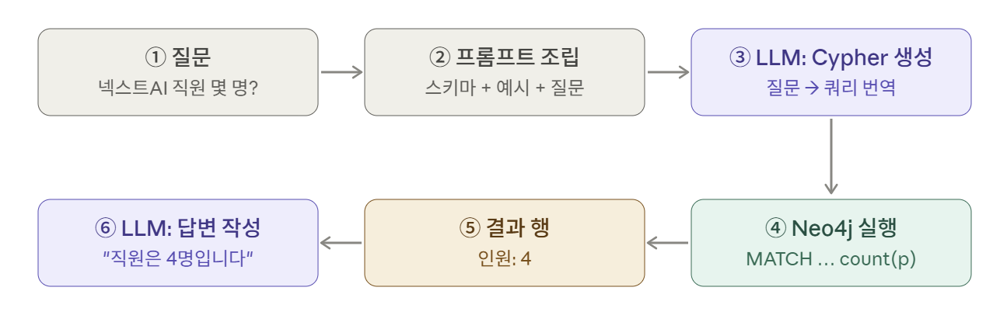

- 2번 단계에서 : LLM은 우리 그래프의 구조를 모릅니다. 그래서 질문과 함께 세 가지를 줍니다.

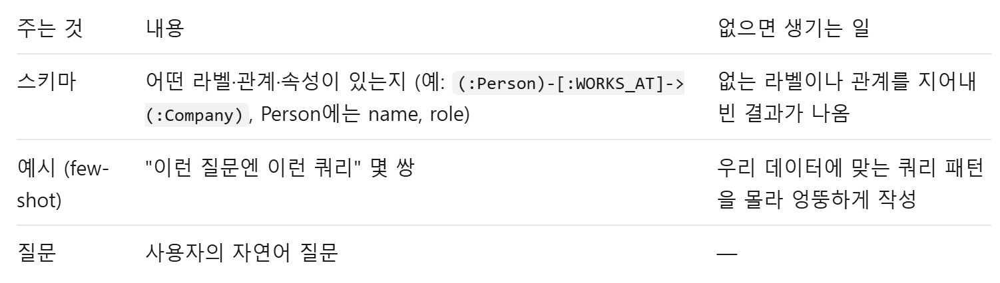

- 그래프 스키마 작성은 직접 할 수도 있고 Text2CypherRetriever 객체 생성시 자동 생성하는 방법을 사용할 수도 있습니다.
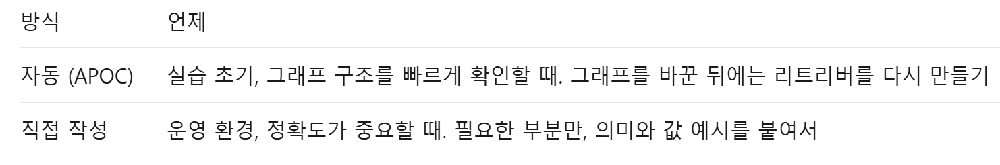

1. Text2CypherRetriever(...)를 만드는 순간 neo4j_schema가 비어 있으면, APOC(apoc.meta.data)으로 DB를 훑어 스키마를 읽어 옵니다.
2. 읽어 온 스키마를 아래와 같은 텍스트로 정리해 저장해 둡니다.
3. 질문할 때마다 이 텍스트를 프롬프트에 넣어 LLM에게 보냅니다.

[ 자동 스키마의 한계 ]

1. 처음 한 번만 읽는다: 그래프가 바뀌어도 예전 스키마를 계속 쓴다.
2. 불필요한 것까지 들어간다: Chunk, FROM_CHUNK, embedding 같은 내부 구조가 섞여 LLM이 헷갈린다.
3. 뜻을 모른다: 이름만 있고 의미("대표 제품 = DEVELOPS 한 Project")나 값 표기("넥스트AI")는 없다.

**실무에서는 자동 스키마를 출력해 초안으로 삼고, 필요 없는 부분은 지우고 설명을 덧붙여 쓰는 방식이 일반적이에요.** 처음부터 다 쓰는 것보다 훨씬 빠릅니다.

In [55]:
# 자동으로 읽어 온 스키마 확인 — Chunk, FROM_CHUNK, embedding 같은 내부 구조도 섞여 있는지 살펴보세요
print(t2c_retriever.neo4j_schema)

Node properties:
Person {name: STRING}
Company {name: STRING}
Project {name: STRING}
Technology {name: STRING}
Document {document_type: STRING, path: STRING, createdAt: STRING}
Chunk {index: INTEGER, text: STRING, embedding: LIST}
Relationship properties:

The relationships:
(:Person)-[:PARTICIPATES_IN]->(:Project)
(:Person)-[:WORKS_AT]->(:Company)
(:Person)-[:KNOWS]->(:Person)
(:Person)-[:FROM_CHUNK]->(:Chunk)
(:Person)-[:HAS_SKILL]->(:Technology)
(:Company)-[:FROM_CHUNK]->(:Chunk)
(:Company)-[:DEVELOPS]->(:Project)
(:Project)-[:USES]->(:Technology)
(:Project)-[:FROM_CHUNK]->(:Chunk)
(:Technology)-[:FROM_CHUNK]->(:Chunk)
(:Chunk)-[:FROM_DOCUMENT]->(:Document)


[ 직접 작성해서 주는 방법 ]

질문에 필요한 부분만 골라 설명을 붙여 넘기면 정확도가 올라갑니다.

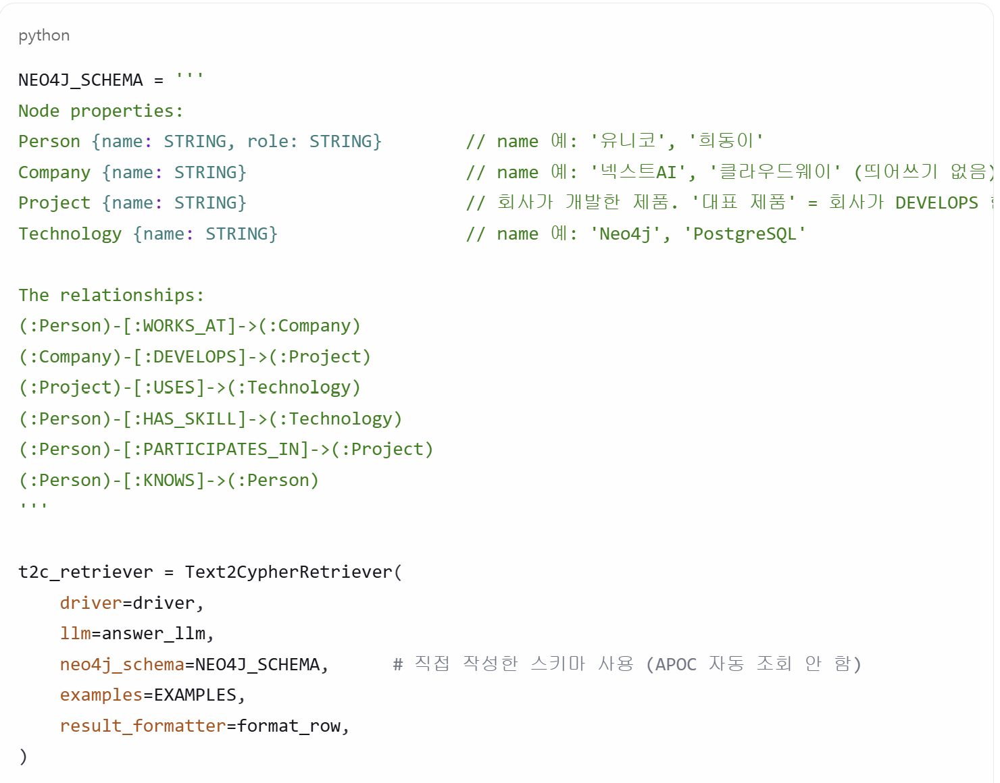

In [56]:
# 직접 작성한 스키마: 질문에 필요한 부분만 + 의미와 값 예시를 주석으로
NEO4J_SCHEMA = '''
Node properties:
Person {name: STRING, role: STRING}        // name 예: '유니코', '희동이'
Company {name: STRING}                     // name 예: '넥스트AI', '클라우드웨이' (띄어쓰기 없음)
Project {name: STRING}                     // 회사가 개발한 제품. '대표 제품' = 회사가 DEVELOPS 한 Project
Technology {name: STRING}                  // name 예: 'Neo4j', 'PostgreSQL'

The relationships:
(:Person)-[:WORKS_AT]->(:Company)
(:Company)-[:DEVELOPS]->(:Project)
(:Project)-[:USES]->(:Technology)
(:Person)-[:HAS_SKILL]->(:Technology)
(:Person)-[:PARTICIPATES_IN]->(:Project)
(:Person)-[:KNOWS]->(:Person)
'''

t2c_manual = Text2CypherRetriever(
    driver=driver,
    llm=answer_llm,
    neo4j_schema=NEO4J_SCHEMA,      # 직접 작성한 스키마 사용 (APOC 자동 조회 안 함)
    examples=EXAMPLES,
    result_formatter=format_row,
)

res = t2c_manual.search(query_text="넥스트AI의 대표 제품은 어떤 기술을 써?")
print("🛠️ 생성된 Cypher :", res.metadata.get("cypher"))
print("📊 조회 결과     :", [item.content for item in res.items])

🛠️ 생성된 Cypher : MATCH (:Company {name:'넥스트AI'})-[:DEVELOPS]->(p:Project)-[:USES]->(t:Technology) RETURN p.name AS 제품, collect(t.name) AS 기술
📊 조회 결과     : ["제품: 스마트상담봇, 기술: ['Neo4j', 'LangGraph']"]


> 💡 **자동 스키마의 한계와 해결**
> | 한계 | 해결 |
> |---|---|
> | ① 처음 한 번만 읽는다 | 그래프를 바꾼 뒤에는 리트리버를 **다시 만든다** |
> | ② 불필요한 내부 구조가 섞인다 | 필요한 부분만 **직접 작성** |
> | ③ 뜻과 값 표기를 모른다 | **직접 작성**(주석으로 설명) 또는 **few-shot 예시**로 보완 |

> ⚠️ **Text2Cypher 보안 수칙** (교안 7.4절)
> LLM이 만든 쿼리는 `DETACH DELETE` 같은 쓰기 쿼리일 수도 있습니다. 운영 환경에서는
> - **읽기 전용 계정**으로 접속하고
> - 직접 실행할 때는 `routing_= RoutingControl.READ`(읽기 트랜잭션)로 실행하며
> - `CREATE`, `MERGE`, `DELETE`, `SET`이 포함된 쿼리는 실행 전에 차단하세요.

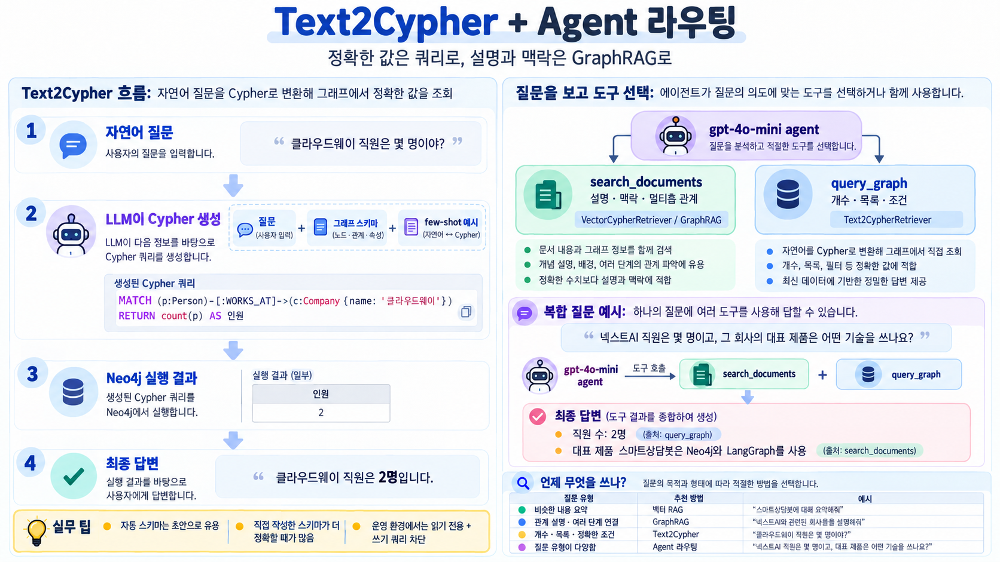

### 15단계. 에이전트가 질문에 맞는 검색 고르기

실무에서는 한 가지 검색만 쓰지 않습니다. 검색 방식을 **도구**로 주면, LLM이 질문을 보고 알맞은 도구를 고릅니다. 도구 설명(docstring)이 곧 고르는 기준입니다. (교안 7.6절)

| 도구 | 쓰임 |
|---|---|
| `search_documents` | 설명·맥락·여러 단계 관계가 필요할 때 → VectorCypher (벡터 검색 + 그래프 확장) |
| `query_graph` | 개수·목록·조건이 필요할 때   → Text2Cypher (질문을 Cypher로 변환) |

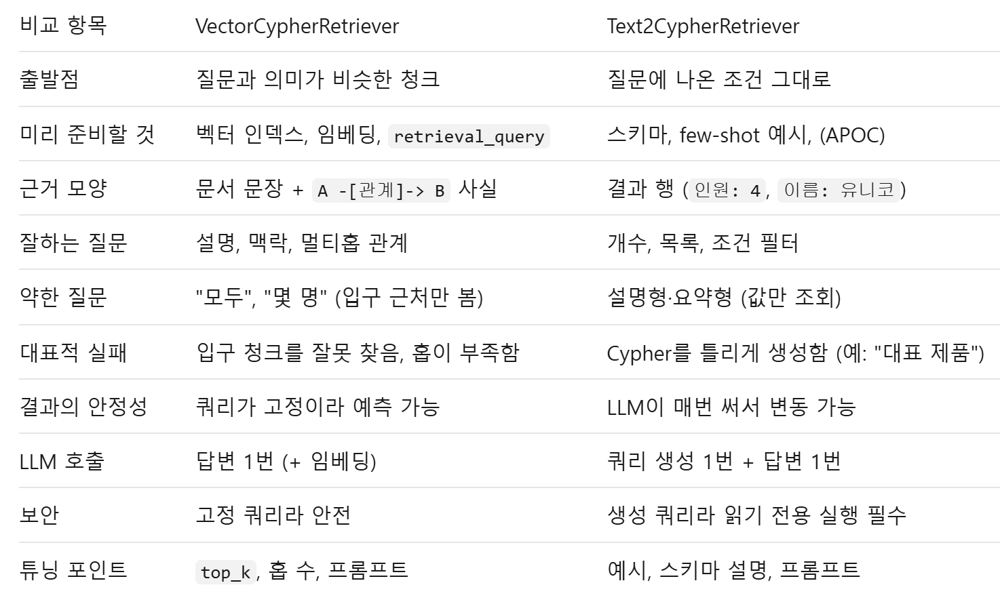

In [57]:
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI

In [58]:
@tool
def search_documents(question: str) -> str:
    "문서의 설명·맥락, 그리고 여러 단계로 이어진 관계(예: 회사의 제품이 쓰는 기술)가 필요할 때 사용한다."
    result = graph_retriever.search(query_text=question, top_k=3)
    return "\n\n".join(str(item.content) for item in result.items) or "검색 결과 없음"


@tool
def query_graph(question: str) -> str:
    "사람·회사·프로젝트·기술의 개수, 목록, 조건 필터처럼 정확한 값이 필요할 때 사용한다."
    try:
        result = t2c_retriever.search(query_text=question)
    except Exception as e:                        # 잘못된 Cypher 가 만들어져도 멈추지 않게
        return f"조회 실패: {e}"
    rows = "\n".join(str(item.content) for item in result.items) or "결과 없음"
    return f"실행한 Cypher: {result.metadata.get('cypher')}\n조회 결과:\n{rows}"


SYSTEM_PROMPT = '''너는 사내 지식 도우미다. 반드시 도구로 확인한 내용만 근거로 한국어로 답한다.
- 질문에 여러 요청이 섞여 있으면 요청별로 나누어 각각 알맞은 도구를 호출한다.
  · 개수·목록·조건 → query_graph
  · 설명·맥락·여러 단계로 이어진 관계 → search_documents
- 도구 결과가 '결과 없음'이거나 '조회 실패'이면, 다른 도구로 한 번 더 확인한다.
- 그래도 없을 때만 "확인할 수 없습니다"라고 답한다.
- 최종 답변은 요청별로 나누어 쓰고, 각 답 옆에 (출처: 도구 이름)을 적는다.'''

agent = create_agent(
    model=ChatOpenAI(model="gpt-4o-mini", temperature=0),
    tools=[search_documents, query_graph],
    system_prompt=SYSTEM_PROMPT,
)

#### 에이전트의 판단 과정 보기
`ask_agent()`는 **🔧 도구 선택 → 📥 도구 결과(근거) → 💬 최종 답변** 순서로 출력해, 에이전트가 왜 그렇게 답했는지 볼 수 있게 합니다.

In [59]:
def ask_agent(question: str):
    print(f"❓ {question}\n")
    for chunk in agent.stream({"messages": [("user", question)]}, stream_mode="updates"):
        for node, update in chunk.items():
            for msg in (update or {}).get("messages", []):
                if msg.type == "ai" and msg.tool_calls:                 # ① 도구 선택
                    for call in msg.tool_calls:
                        print(f"🔧 도구 선택: {call['name']}({call['args'].get('question')})")
                elif msg.type == "tool":                                # ② 도구 결과 (근거)
                    preview = msg.text if len(msg.text) < 400 else msg.text[:400] + " …"
                    print(f"📥 [{msg.name}] 결과\n   " + preview.replace("\n", "\n   ") + "\n")
                elif msg.type == "ai":                                  # ③ 최종 답변
                    print(f"💬 최종 답변\n{msg.text}\n")


ask_agent("넥스트AI 직원은 몇 명이고, 그 회사의 대표 제품은 어떤 기술을 쓰나요?")

❓ 넥스트AI 직원은 몇 명이고, 그 회사의 대표 제품은 어떤 기술을 쓰나요?

🔧 도구 선택: query_graph(넥스트AI 직원 수)
🔧 도구 선택: search_documents(넥스트AI의 대표 제품과 사용하는 기술)
📥 [search_documents] 결과
   [문서]
   넥스트AI는 2019년에 설립된 AI 상담 솔루션 회사다. 본사는 서울 성수동에 있다. 넥스트AI는 2026년에 대표 제품인 스마트상담봇을 출시했다.
   [관계 사실]
   - 도우너 -[WORKS_AT]-> 넥스트AI
   - 도우너 -[KNOWS]-> 유니코
   - 도우너 -[KNOWS]-> 둘리
   - 도우너 -[PARTICIPATES_IN]-> 스마트상담봇
   - 유니코 -[WORKS_AT]-> 넥스트AI
   - 유니코 -[HAS_SKILL]-> Python
   - 유니코 -[PARTICIPATES_IN]-> 스마트상담봇
   - 유니코 -[HAS_SKILL]-> Neo4j
   - 넥스트AI -[DEVELOPS]-> 스마트상담봇
   - 스마트상담봇 -[USES]-> LangGraph
   - 마이콜 -[PARTICIPATES_IN]-> 스마 …

📥 [query_graph] 결과
   실행한 Cypher: MATCH (p:Person)-[:WORKS_AT]->(c:Company {name:'넥스트AI'}) RETURN count(p) AS 직원수
   조회 결과:
   직원수: 4

💬 최종 답변
넥스트AI 직원 수는 4명입니다. (출처: query_graph)

넥스트AI의 대표 제품은 스마트상담봇이며, 이 제품은 LangGraph와 Neo4j 기술을 사용합니다. (출처: search_documents)



**📝 정리** — 에이전트가 요청을 나눠 `query_graph`(직원 수 4명)와 `search_documents`(대표 제품의 기술)를 둘 다 호출하고 출처를 붙였다.

#### 최종 답변만 받기
과정은 숨기고 답만 필요할 때는 `invoke`로 끝까지 실행한 뒤 **마지막 메시지**를 꺼냅니다.

In [60]:
question = "PostgreSQL을 쓰는 프로젝트에는 누가 참여하고, 그 프로젝트는 어느 회사가 개발했나요?"

result = agent.invoke({"messages": [("user", question)]})
print(result["messages"][-1].text)        # 마지막 메시지 = 최종 답변

1. PostgreSQL을 사용하는 프로젝트의 참여자는 둘리와 또치입니다. (출처: query_graph)

2. PostgreSQL을 사용하는 프로젝트는 클라우드웨이에서 개발한 문서검색엔진입니다. (출처: query_graph)


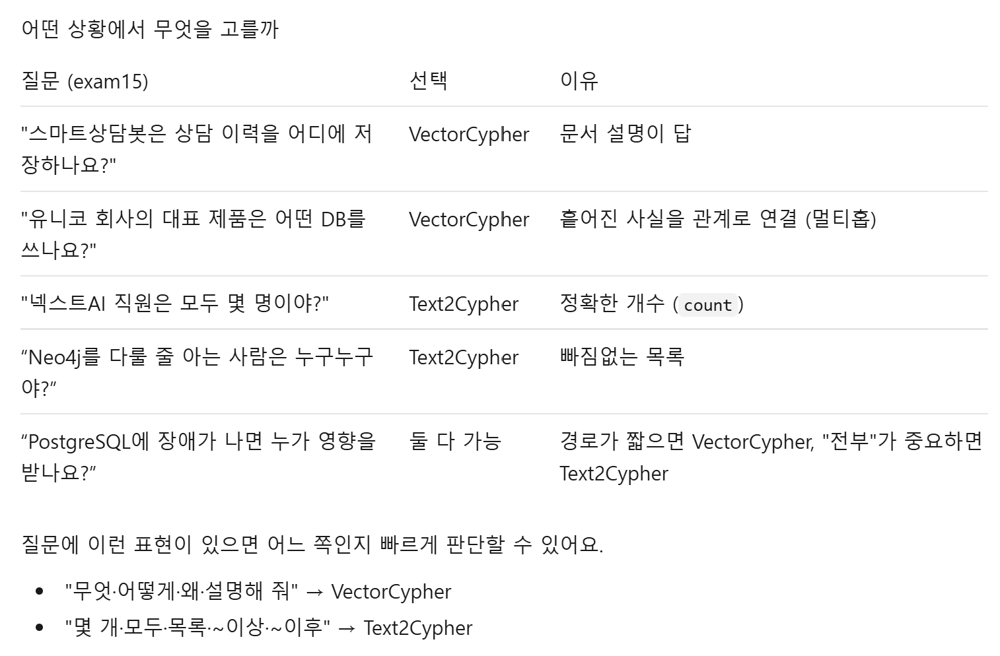

---
## 마무리

### 그래프 DB와 GraphRAG의 장점 정리

| 장점 | 실습 단계 | 벡터 RAG(pgvector)와 비교 |
|---|---|---|
| 관계를 데이터로 저장하고 그림처럼 질의 | 1, 4 | 벡터 RAG는 청크 사이의 관계를 저장하지 않음 |
| 멀티홉 질문 | 5, 13-② | 흩어진 사실 중 일부를 놓치기 쉬움 |
| 경로 탐색 | 6 | 경로 계산 불가 |
| 정확한 집계·목록 | 7, 13-③, 14 | Top-k 밖은 누락 |
| 유연한 스키마 | 8 | (관계형 DB는 테이블 변경 필요) |
| 근거 추적 | 11, 13 | 청크 단위 근거만 가능 |
| 벡터 검색 + 그래프 탐색을 한 쿼리로 | 12, 13 | 별도 시스템 간 연결 필요 |

### 언제 무엇을?
- **비슷한 내용 찾기·요약** → 벡터 RAG로 충분 (가장 저렴하고 빠름)
- **설명·맥락·여러 단계 관계** → VectorCypherRetriever (벡터 검색 + 그래프 확장)
- **개수·목록·조건** → Text2CypherRetriever (질문을 Cypher로 변환)
- **질문 유형이 다양함** → 에이전트로 라우팅 (15단계)

> 💡 **도입 전략**: 벡터 RAG로 시작하고, 틀리는 질문이 **관계 때문**이라면 그 관계만 그래프로 옮기세요.

**벡터 RAG는 "비슷한 문장"을, GraphRAG는 "이어진 사실"을, Text2Cypher는 "정확한 값"을 찾는다.**

In [61]:
# 실습 종료 — 드라이버 연결 닫기
driver.close()

## 🔁 복습 질문

<details>
<summary>1. 같은 적재 셀을 두 번 실행해도 노드가 늘지 않게 하려면?</summary>

`MERGE` + 유일성 제약. MERGE에는 고유 키만 넣고 나머지는 `SET`.
</details>

<details>
<summary>2. 벡터 RAG가 멀티홉 질문에 약한 이유는?</summary>

필요한 사실이 여러 문서에 흩어져 있어 Top-k 청크에 다 들어오지 않는다.
</details>

<details>
<summary>3. GraphRAG 답이 틀렸을 때 확인 순서는?</summary>

① 그래프에 사실이 있나 → ② 검색 context에 들어갔나 → ③ 답변 LLM이 썼나.
</details>

<details>
<summary>4. Text2Cypher 운영 시 보안 조치는?</summary>

읽기 전용 계정·읽기 트랜잭션, 쓰기 키워드(CREATE/MERGE/DELETE/SET) 쿼리 차단.
</details>
